# Chaos Classification of BTC Returns and Volatility

**Question.** Daily BTC returns look random (see `chaos_classification.ipynb`). Does **volatility** show
nonlinear or even chaotic behaviour?

Four series are analysed with the same tools:

| Series | Definition | What it measures |
|---|---|---|
| returns | $r_t = \ln P_t - \ln P_{t-1}$ | direction and size of the daily move |
| absolute returns | $\lvert r_t\rvert$ | daily volatility proxy |
| squared returns | $r_t^2$ | daily variance proxy |
| 20-day realised volatility | $RV_t = \sqrt{\tfrac{1}{20}\sum_{i=0}^{19} r_{t-i}^2}$ | smoothed volatility |

**Two different questions are kept apart throughout:**
1. *Nonlinearity*: is there dependence that a linear Gaussian process (IAAFT surrogate) cannot produce?
2. *Deterministic chaos*: is the nonlinearity also beyond a **stochastic** volatility model (GARCH surrogate),
   with a low-dimensional attractor, positive divergence and agreement across tests?

Volatility clustering is nonlinear but random, so a series can be clearly nonlinear and still fully explained by
GARCH. Only evidence beyond GARCH can point towards deterministic dynamics.

## 0. Settings

In [1]:
DATA_FILE = "../data/BTC/BTC_1d.csv"   # read only
DATE_COL, PRICE_COL = "open_time", "close"
START, END = None, "2026-09-02"        # last complete day in the file
RV_WINDOW = 20

SEED = 20261103
N_SURR = 999          # surrogates per family and series: smallest two-sided p = 0.002
N_SURR_HALF = 499     # for the split-sample stability check: smallest two-sided p = 0.004
ALPHA = 0.05
M_MAX, MAX_LAG = 10, 30

In [2]:
import time, warnings
import matplotlib
import matplotlib.dates
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from statsmodels.tsa.stattools import adfuller, kpss

import nla_tools as T

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8987"
FIG = Path("figures/volatility"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load prices (read only) and build the four series

The same transformation is later applied to every GARCH-simulated return path, so data and GARCH surrogates
are always compared like for like (for example, a GARCH surrogate of realised volatility is the 20-day realised
volatility of a simulated GARCH return path).

In [3]:
raw = pd.read_csv(DATA_FILE)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL], utc=True).dt.tz_localize(None)
price = raw.set_index(DATE_COL).sort_index().loc[START:END, PRICE_COL].astype(float)
r_full = np.log(price).diff().dropna()

def make_series(r):
    """Four series from a return array; all trimmed to the same dates (RV needs RV_WINDOW - 1 extra days)."""
    r = np.asarray(r, float)
    rv = np.sqrt(pd.Series(r ** 2).rolling(RV_WINDOW).mean().values)
    k = RV_WINDOW - 1
    return {"returns": r[k:], "absolute returns": np.abs(r[k:]), "squared returns": r[k:] ** 2, "realised vol (20d)": rv[k:]}

S = make_series(r_full.values)
dates = r_full.index[RV_WINDOW - 1:]
NAMES = list(S)
print(f"{DATA_FILE}: {dates[0].date()} to {dates[-1].date()}, n = {len(dates)} days per series")
pd.DataFrame({k: pd.Series(v).describe() for k, v in S.items()}).T.round(5)

../data/BTC/BTC_1d.csv: 2017-09-06 to 2026-09-02, n = 3284 days per series


,count,mean,std,min,25%,50%,75%,max
returns,3284.0,0.00088,0.03541,-0.50261,-0.01396,0.00056,0.01545,0.20295
absolute returns,3284.0,0.02322,0.02675,0.00001,0.00608,0.01482,0.03063,0.50261
squared returns,3284.0,0.00125,0.00531,0.00000,0.00004,0.00022,0.00094,0.25261
realised vol (20d),3284.0,0.03170,0.01595,0.00582,0.02084,0.02859,0.03847,0.13012


### Stationarity
ADF (null: unit root) and KPSS (null: stationary). Surrogate tests assume a stationary process; volatility
regimes are a form of non-stationarity, which is one reason a linear surrogate can be rejected without any
chaos. The split-sample check in section 7 addresses this.

In [4]:
st_rows = []
for k, v in S.items():
    st_rows.append({"series": k, "ADF p": adfuller(v, autolag="AIC")[1], "KPSS p": kpss(v, regression="c", nlags="auto")[1]})
stat_tab = pd.DataFrame(st_rows)
stat_tab["reading"] = np.where((stat_tab["ADF p"] < 0.05) & (stat_tab["KPSS p"] > 0.05), "stationary",
                               np.where(stat_tab["ADF p"] < 0.05, "ADF rejects unit root, KPSS rejects stationarity: persistent / long memory", "unit root"))
stat_tab.round(4)

,series,ADF p,KPSS p,reading
0,returns,0.0,0.10,stationary
1,absolute returns,0.0,0.01,"ADF rejects unit root, KPSS rejects stationari..."
2,squared returns,0.0,0.01,"ADF rejects unit root, KPSS rejects stationari..."
3,realised vol (20d),0.0,0.01,"ADF rejects unit root, KPSS rejects stationari..."


## 2. Visual inspection

Six views of each series: time plot, autocorrelation, lag plot ($x_t$ vs $x_{t+1}$), 2-d and 3-d delay
reconstruction, and a recurrence plot. Delays are estimated in section 3 and used here.

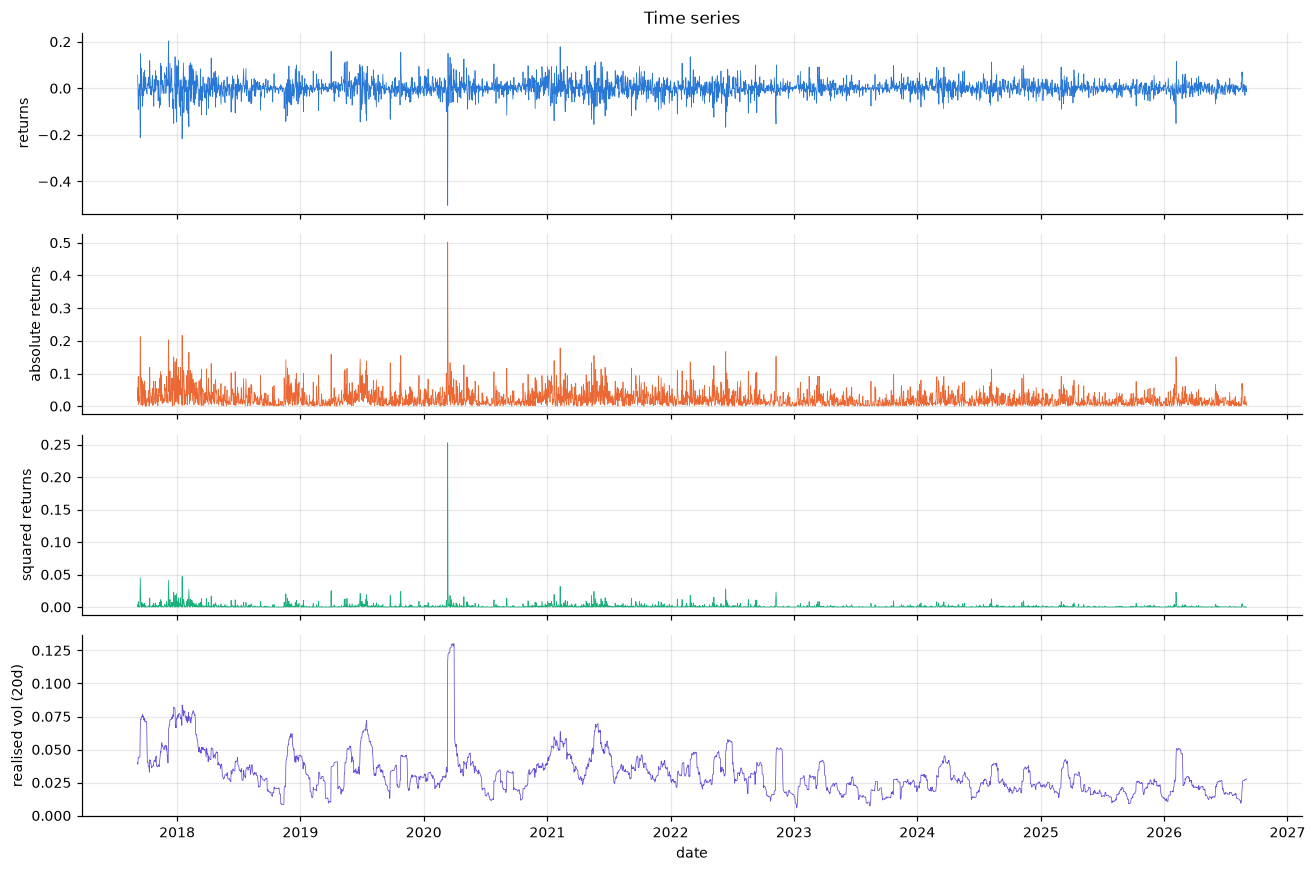

In [5]:
emb = {}
for k, v in S.items():
    z = (v - v.mean()) / v.std()
    tau, t_ami, t_acf, A = T.choose_tau(z, MAX_LAG)
    theiler = max(10, 2 * tau, RV_WINDOW if k.startswith("realised") else 0)
    F = T.fnn(z, tau, M_MAX, theiler=theiler)
    m, reached = T.choose_m(F)
    emb[k] = {"z": z, "tau": tau, "tau_ami": t_ami, "tau_acf": t_acf, "ami": A, "fnn": F, "m": m,
              "fnn_reached": reached, "theiler": theiler}

fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a, (k, v), col in zip(ax, S.items(), [BLUE, ORANGE, GREEN, "#6250d6"]):
    a.plot(dates, v, lw=0.5, color=col); a.set(ylabel=k, title=k if a is ax[0] else None)
ax[0].set_title("Time series"); ax[-1].set_xlabel("date")
save(fig, "01_time_series")

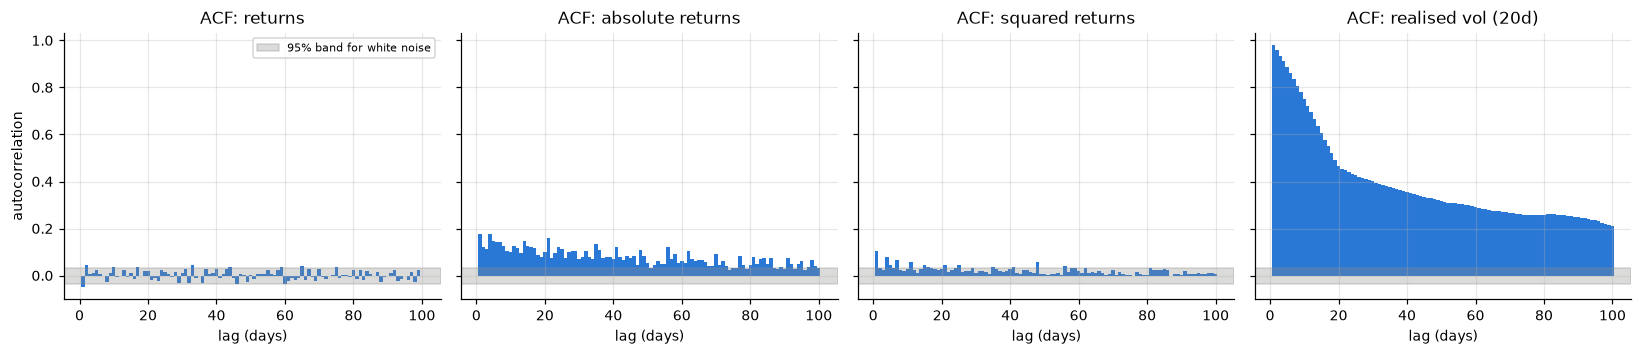

In [6]:
L = 100
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
for a, k in zip(ax, NAMES):
    ac = T.acf(S[k], L)
    a.bar(range(1, L + 1), ac[1:], width=1.0, color=BLUE)
    band = 1.96 / np.sqrt(len(S[k]))
    a.axhspan(-band, band, color=GREY, alpha=0.3, label="95% band for white noise")
    a.set(title=f"ACF: {k}", xlabel="lag (days)", ylabel="autocorrelation" if a is ax[0] else None)
ax[0].legend(fontsize=7)
save(fig, "02_acf")

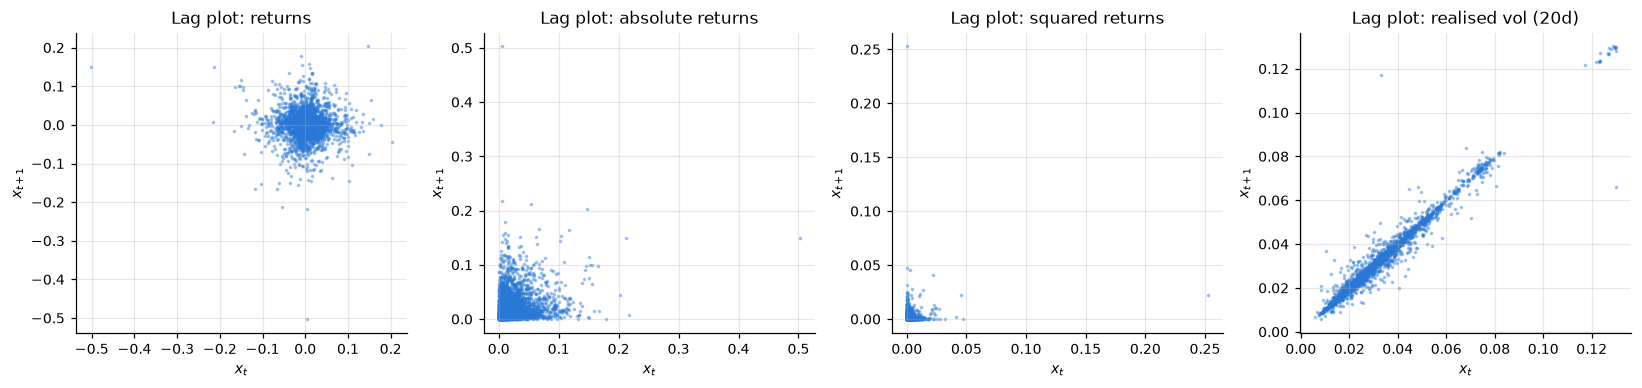

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, k in zip(ax, NAMES):
    v = S[k]
    a.scatter(v[:-1], v[1:], s=2, alpha=0.35, color=BLUE)
    a.set(title=f"Lag plot: {k}", xlabel="$x_t$", ylabel="$x_{t+1}$")
save(fig, "03_lag_plots")

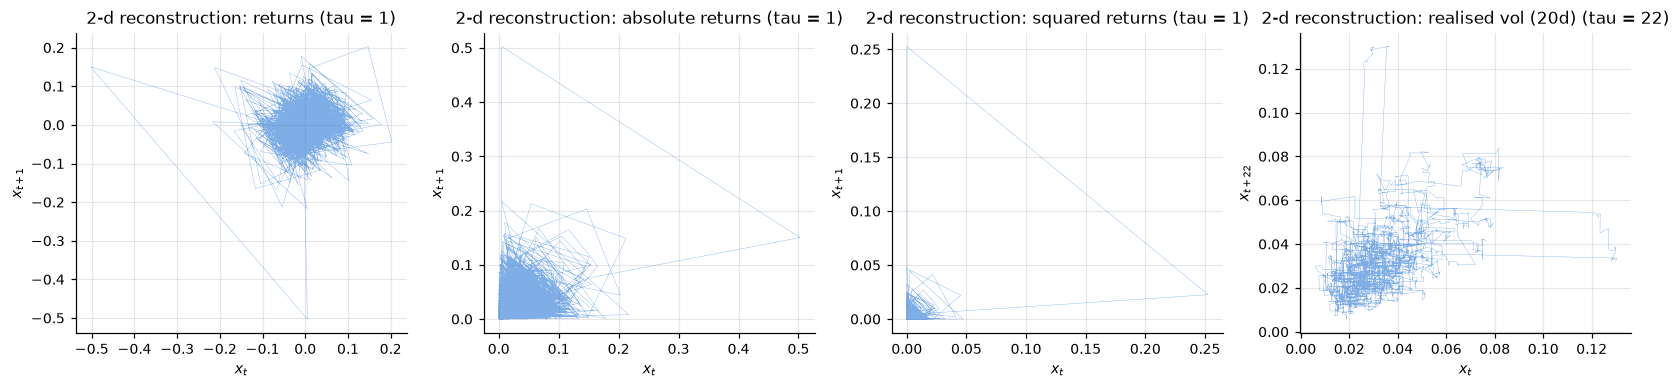

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, k in zip(ax, NAMES):
    v, t = S[k], emb[k]["tau"]
    a.plot(v[:-t], v[t:], lw=0.25, color=BLUE, alpha=0.6)
    a.set(title=f"2-d reconstruction: {k} (tau = {t})", xlabel="$x_t$", ylabel=f"$x_{{t+{t}}}$")
save(fig, "04_phase_2d")

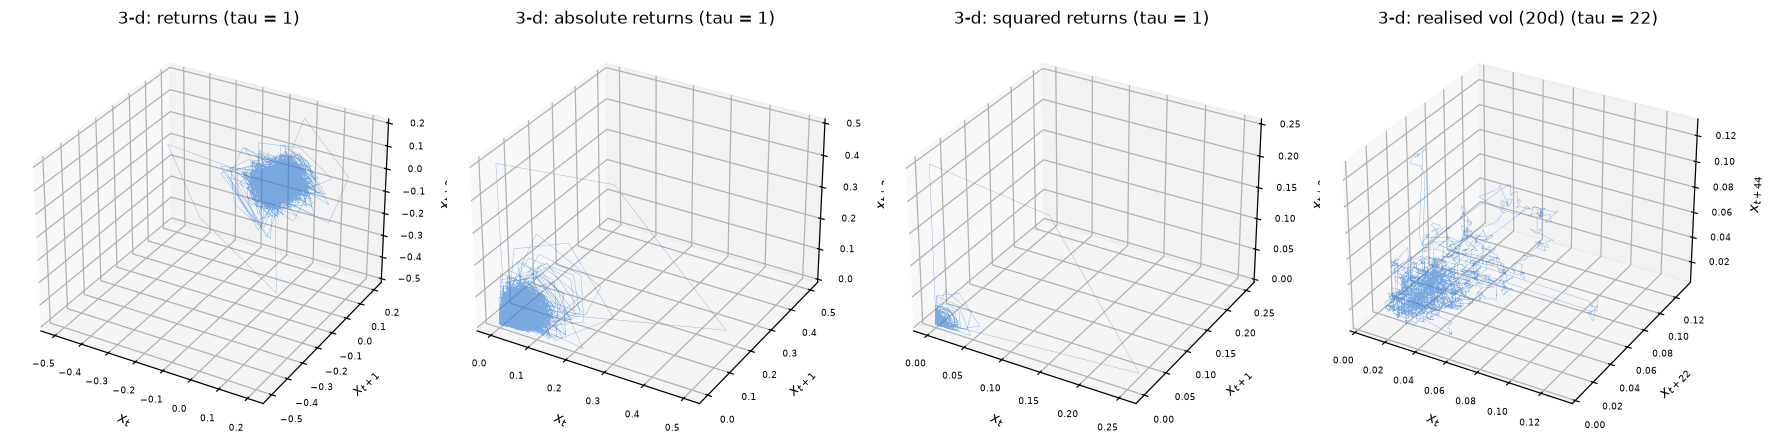

In [9]:
fig = plt.figure(figsize=(16, 4.4))
for i, k in enumerate(NAMES):
    v, t = S[k], emb[k]["tau"]
    Y = T.embed(v, 3, t)
    a = fig.add_subplot(1, 4, i + 1, projection="3d")
    a.plot(Y[:, 0], Y[:, 1], Y[:, 2], lw=0.25, color=BLUE, alpha=0.6)
    a.set(title=f"3-d: {k} (tau = {t})", xlabel="$x_t$", ylabel=f"$x_{{t+{t}}}$", zlabel=f"$x_{{t+{2*t}}}$")
    a.tick_params(labelsize=6)
save(fig, "05_phase_3d")

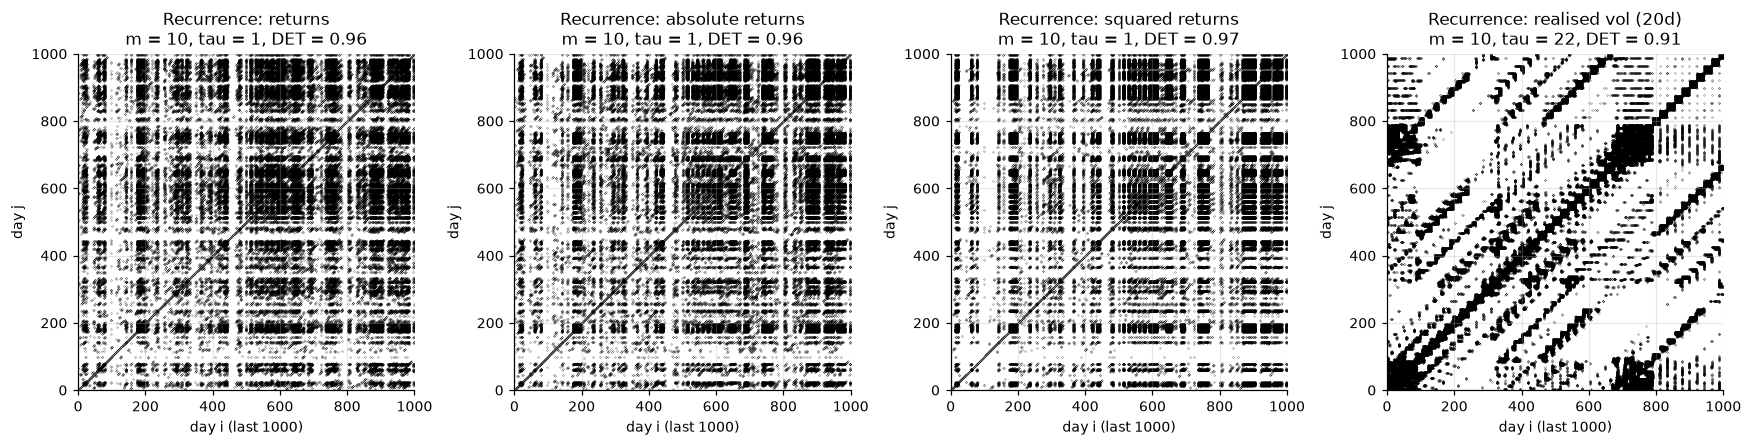

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
DET = {}
for a, k in zip(ax, NAMES):
    e = emb[k]
    R = T.recurrence_matrix(e["z"], e["m"], e["tau"], 1000, 0.10)
    DET[k] = T.det(R, theiler=1)
    i, j = np.nonzero(R)
    a.scatter(i, j, s=0.03, color="black")
    a.set(title=f"Recurrence: {k}\nm = {e['m']}, tau = {e['tau']}, DET = {DET[k]:.2f}", xlabel="day i (last 1000)",
          ylabel="day j", xlim=(0, 1000), ylim=(0, 1000))
    a.set_aspect("equal")
save(fig, "06_recurrence")

Reading the plots: volatility series have strong, slowly decaying autocorrelation (volatility clustering),
their lag plots are tilted wedges rather than thin curves, and their recurrence plots show square blocks
(calm and turbulent periods) rather than long diagonal lines. Persistence is visible; a low-dimensional
deterministic shape is not. These impressions are tested formally below.

## 3. Reconstruction parameters: AMI (tau) and FNN (m)

tau = min(first AMI minimum, first lag with |ACF| < 1/e). For realised volatility the overlapping 20-day window
creates strong autocorrelation by construction, so its Theiler window (temporal neighbours excluded from
neighbour searches) is at least 20 days.

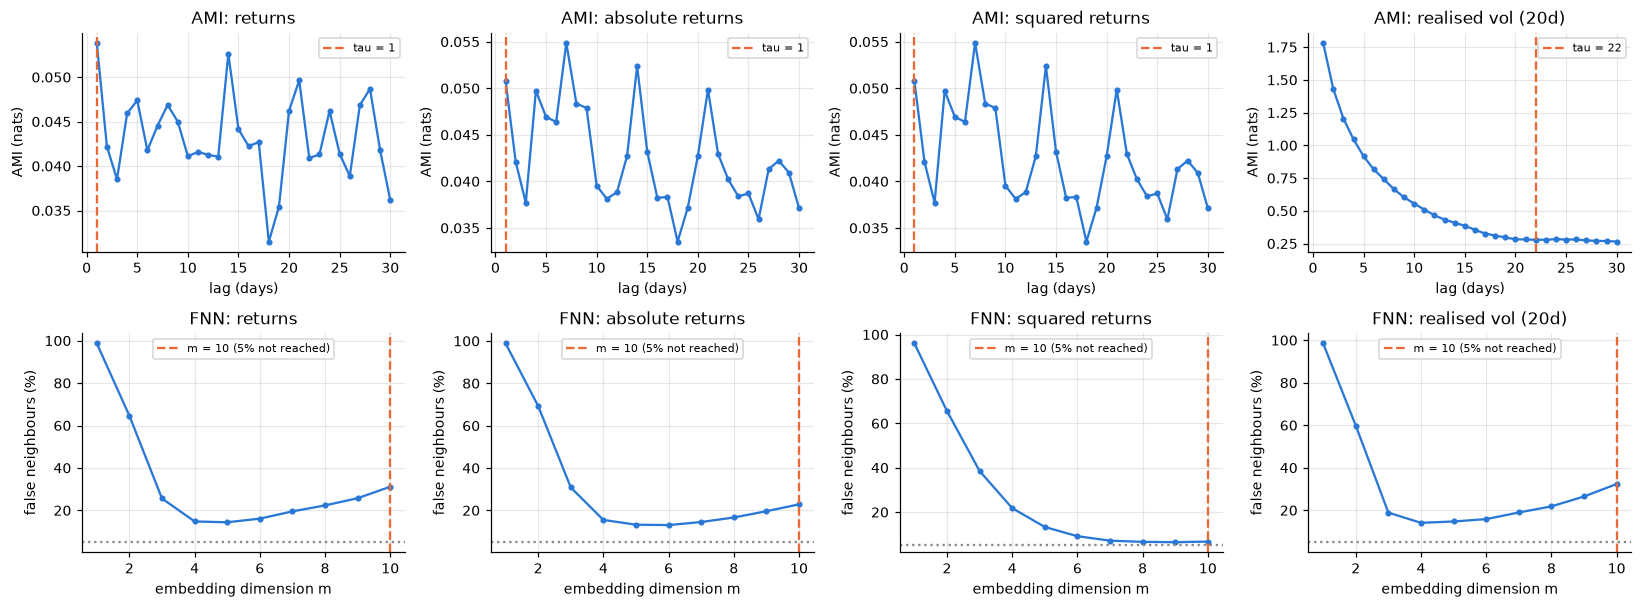

,series,tau (AMI min),tau (ACF 1/e),tau used,FNN min (%),m used,FNN reached 5%,Theiler window
0,returns,3,1,1,14.4,10,False,10
1,absolute returns,3,1,1,13.1,10,False,10
2,squared returns,3,1,1,6.5,10,False,10
3,realised vol (20d),22,30,22,14.1,10,False,44


In [11]:
fig, ax = plt.subplots(2, 4, figsize=(15, 5.6))
for i, k in enumerate(NAMES):
    e = emb[k]
    ax[0, i].plot(range(1, MAX_LAG + 1), e["ami"][1:], "o-", ms=3, color=BLUE)
    ax[0, i].axvline(e["tau"], color=ORANGE, ls="--", label=f"tau = {e['tau']}")
    ax[0, i].set(title=f"AMI: {k}", xlabel="lag (days)", ylabel="AMI (nats)"); ax[0, i].legend(fontsize=7)
    ax[1, i].plot(range(1, M_MAX + 1), e["fnn"] * 100, "o-", ms=3, color=BLUE)
    ax[1, i].axhline(5, color=GREY, ls=":")
    ax[1, i].axvline(e["m"], color=ORANGE, ls="--", label=f"m = {e['m']}" + ("" if e["fnn_reached"] else " (5% not reached)"))
    ax[1, i].set(title=f"FNN: {k}", xlabel="embedding dimension m", ylabel="false neighbours (%)"); ax[1, i].legend(fontsize=7)
save(fig, "07_ami_fnn")
pd.DataFrame([{"series": k, "tau (AMI min)": e["tau_ami"], "tau (ACF 1/e)": e["tau_acf"], "tau used": e["tau"],
               "FNN min (%)": round(e["fnn"].min() * 100, 1), "m used": e["m"], "FNN reached 5%": e["fnn_reached"],
               "Theiler window": e["theiler"]} for k, e in emb.items()])

## 4. Chaos diagnostics on the data

- **Largest Lyapunov exponent** (Rosenstein): slope of the mean log divergence of nearest neighbours.
  A positive value is **not** proof of chaos: random series also give positive values.
- **Correlation dimension** D2 for m = 1..10, with the saturation rule (some run of three consecutive m with
  spread below 15% of the mean and mean below m - 1).
- **0-1 test** K (near 0 regular, near 1 irregular = chaos **or** noise). Strongly autocorrelated series are
  "oversampled" and push K towards 0 artificially, so the test is applied to the series sampled every tau days.

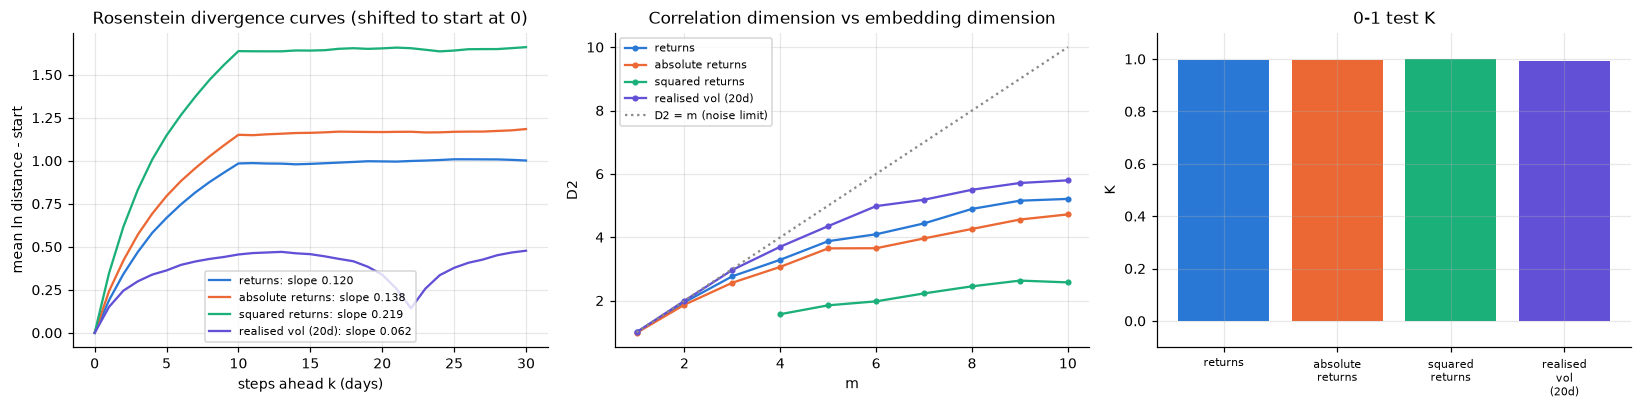

,series,Lyapunov (per day),fit R^2,fit range k,D2 by m,D2 saturates,D2,K (0-1 test),DET
0,returns,0.1196,0.9894,"(1, 5)","[1.0, 1.95, 2.77, 3.29, 3.88, 4.09, 4.44, 4.89...",True,4.1363,0.9975,0.9630
1,absolute returns,0.1377,0.9880,"(1, 5)","[0.98, 1.87, 2.57, 3.07, 3.65, 3.65, 3.96, 4.2...",True,3.7555,0.9968,0.9649
2,squared returns,0.2193,0.9907,"(1, 4)","[nan, nan, nan, 1.57, 1.85, 1.98, 2.23, 2.45, ...",True,2.5529,0.9992,0.9665
3,realised vol (20d),0.0616,0.9597,"(1, 4)","[1.0, 1.99, 2.97, 3.7, 4.35, 4.98, 5.18, 5.5, ...",True,5.2223,0.9939,0.9084


In [12]:
diag = {}
for k in NAMES:
    e = emb[k]
    lle, r2, rng_, cur = T.lyapunov(e["z"], e["m"], e["tau"], e["theiler"])
    d2, sat, d2v, curves = T.correlation_dimension(e["z"], e["tau"], e["theiler"])
    K, walk = T.zero_one(S[k][:: e["tau"]], 50)
    diag[k] = {"lle": lle, "r2": r2, "range": rng_, "curve": cur, "d2": d2, "sat": sat, "d2v": d2v, "K": K, "walk": walk}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k, col in zip(NAMES, [BLUE, ORANGE, GREEN, "#6250d6"]):
    d = diag[k]
    ax[0].plot(d["curve"] - d["curve"][0], color=col, label=f"{k}: slope {d['lle']:.3f}")
    ax[1].plot(range(1, 11), d["d2"], "o-", ms=3, color=col, label=k)
ax[0].set(title="Rosenstein divergence curves (shifted to start at 0)", xlabel="steps ahead k (days)", ylabel="mean ln distance - start"); ax[0].legend(fontsize=7)
ax[1].plot(range(1, 11), range(1, 11), ":", color=GREY, label="D2 = m (noise limit)")
ax[1].set(title="Correlation dimension vs embedding dimension", xlabel="m", ylabel="D2"); ax[1].legend(fontsize=7)
ax[2].bar(range(4), [diag[k]["K"] for k in NAMES], color=[BLUE, ORANGE, GREEN, "#6250d6"])
ax[2].set_xticks(range(4)); ax[2].set_xticklabels([n.replace(" ", "\n") for n in NAMES], fontsize=7)
ax[2].set(title="0-1 test K", ylabel="K", ylim=(-0.1, 1.1))
save(fig, "08_chaos_diagnostics")
pd.DataFrame([{"series": k, "Lyapunov (per day)": d["lle"], "fit R^2": d["r2"], "fit range k": d["range"],
               "D2 by m": np.round(d["d2"], 2).tolist(), "D2 saturates": d["sat"], "D2": d["d2v"], "K (0-1 test)": d["K"],
               "DET": DET[k]} for k, d in diag.items()]).round(4)

## 5. Surrogate data tests: IAAFT and GARCH

| Surrogate | Built from | Keeps | A rejection means |
|---|---|---|---|
| IAAFT | the series itself | exact distribution and power spectrum (all linear autocorrelation) | nonlinear dependence (or non-stationarity) |
| GARCH(1,1)-t | returns simulated from a GARCH model fitted to BTC, then transformed exactly like the data | fat tails and volatility clustering | structure beyond a standard stochastic volatility model |

Statistics (the direction that would indicate structure):

| Statistic | Type | Test |
|---|---|---|
| Lyapunov exponent | chaos | two-sided |
| D2 at m = 5 | chaos | lower than surrogates |
| 0-1 test K | chaos | two-sided |
| simplex prediction skill | nonlinearity / determinism | higher than surrogates |
| S-map nonlinearity gain | nonlinearity | higher than surrogates |
| time-reversal asymmetry | nonlinearity | two-sided |

999 surrogates per family and series; Benjamini-Hochberg FDR over all 48 tests (4 series x 6 statistics x 2 families).

Why 999: a rank-based p-value can never be smaller than 1/(N+1) one-sided or 2/(N+1) two-sided. A first run with
99 surrogates had a floor of 0.02, which cannot survive FDR control over 48 tests unless many tests sit at the
floor, so even a statistic 17 standard deviations away from its surrogates was reported as not significant.
With 999 surrogates the floor is 0.002. This changes the resolution of the test, not the statistics or the rule.

In [13]:
STATS = {"lyapunov": "two-sided", "D2_m5": "less", "K_01": "two-sided", "pred_skill": "greater", "nl_gain": "greater", "time_reversal": "two-sided"}
KIND = {"lyapunov": "chaos", "D2_m5": "chaos", "K_01": "chaos", "pred_skill": "nonlinearity", "nl_gain": "nonlinearity", "time_reversal": "nonlinearity"}

def statistics(v, e, tau01):
    z = (v - v.mean()) / v.std()
    rr, C = T.corr_sum(z, 5, e["tau"], e["theiler"])
    return {"lyapunov": T.lyapunov(z, e["m"], e["tau"], e["theiler"])[0], "D2_m5": T.d2_slope(rr, C),
            "K_01": T.zero_one(v[::tau01], 20)[0], "pred_skill": T.simplex_skill(z, e["m"], e["tau"]),
            "nl_gain": T.smap_gain(z, e["m"], e["tau"]), "time_reversal": T.time_reversal(z)}

def surrogate(kind, name, series_dict_fn, r, i, seed, garch):
    rs = np.random.default_rng([seed, ["iaaft", "garch"].index(kind), NAMES.index(name), i])
    if kind == "iaaft":
        return T.iaaft(series_dict_fn(r)[name], rs)
    return series_dict_fn(garch.simulate(len(r), rs))[name]

def run_tests(r, n_surr, seed, label):
    """All statistics on the data and on n_surr surrogates of each family, for the four series built from r."""
    Sd = make_series(r)
    garch = T.Garch(r)
    rows, nulls = [], {}
    for k in NAMES:
        e = {**emb[k]}
        obs = statistics(Sd[k], e, e["tau"])
        for kind in ["iaaft", "garch"]:
            sur = Parallel(n_jobs=-1)(delayed(lambda i: statistics(surrogate(kind, k, make_series, r, i, seed, garch), e, e["tau"]))(i) for i in range(n_surr))
            nd = pd.DataFrame(sur); nulls[(k, kind)] = nd
            for st, dirn in STATS.items():
                nv = nd[st].values
                rows.append({"sample": label, "series": k, "surrogate": kind.upper(), "statistic": st, "type": KIND[st],
                             "observed": obs[st], "surr mean": np.nanmean(nv), "surr 2.5%": np.nanquantile(nv, 0.025),
                             "surr 97.5%": np.nanquantile(nv, 0.975), "z": (obs[st] - np.nanmean(nv)) / np.nanstd(nv, ddof=1),
                             "p": T.p_value(obs[st], nv, dirn), "test": dirn})
    tab = pd.DataFrame(rows)
    tab["q (BH)"] = T.bh(tab["p"].values)
    tab["significant"] = tab["q (BH)"] < ALPHA
    return tab, nulls, garch

t0 = time.time()
r_used = r_full.values
TESTS, NULLS, GARCH = run_tests(r_used, N_SURR, SEED, "full")
print(f"surrogate tests: {time.time() - t0:.0f} s")
print("GARCH(1,1)-t parameters (returns scaled to unit variance):", GARCH.params.round(4).to_dict())
TESTS.pivot_table(index=["series", "statistic"], columns="surrogate", values=["observed", "z", "q (BH)"], sort=False).round(3)

surrogate tests: 6207 s
GARCH(1,1)-t parameters (returns scaled to unit variance): {'mu': 0.0207, 'omega': 0.0106, 'alpha[1]': 0.0725, 'beta[1]': 0.9275, 'nu': 3.199}


observed              z        q (BH)       
surrogate                           IAAFT  GARCH   IAAFT  GARCH  IAAFT  GARCH
series             statistic                                                 
returns            lyapunov         0.120  0.120  -2.057  1.776  0.024  0.248
                   D2_m5            3.877  3.877  -2.497 -1.542  0.048  0.248
                   K_01             0.996  0.996  -1.757 -0.017  0.248  0.675
                   pred_skill       0.060  0.060   1.668  1.409  0.236  0.248
                   nl_gain          0.005  0.005   1.602 -0.118  0.236  0.675
                   time_reversal    0.556  0.556   5.442  0.908  0.024  0.393
absolute returns   lyapunov         0.138  0.138  -1.699 -0.348  0.024  0.862
                   D2_m5            3.649  3.649   1.730 -0.156  0.973  0.675
                   K_01             0.997  0.997  -1.044  0.093  0.442  0.829
                   pred_skill       0.119  0.119  -0.552 -0.983  0.862  0.937
                   nl_gain          0.006  0.006   0.290 -0.048  0.589  0.613
                   time_reversal    0.598  0.598   2.949  0.336  0.038  0.672
squared returns    lyapunov         0.219  0.219  -0.309  2.829  0.713  0.224
                   D2_m5            1.852  1.852  -1.769 -1.375  0.224  0.248
                   K_01             0.999  0.999   0.351  0.239  0.973  0.366
                   pred_skill       0.079  0.079   0.371 -0.206  0.568  0.721
                   nl_gain          0.146  0.146   1.857  0.409  0.048  0.248
                   time_reversal    3.383  3.383   0.913  1.644  0.696  0.248
realised vol (20d) lyapunov         0.062  0.062  -1.038  0.235  0.552  0.942
                   D2_m5            4.352  4.352   0.747  1.583  0.928  0.973
                   K_01             0.994  0.994  -1.211  0.265  0.365  0.937
                   pred_skill       0.690  0.690  -2.268 -1.697  0.973  0.973
                   nl_gain          0.021  0.021  -0.401  0.556  0.724  0.248
                   time_reversal    3.634  3.634  18.634  0.006  0.024  0.862

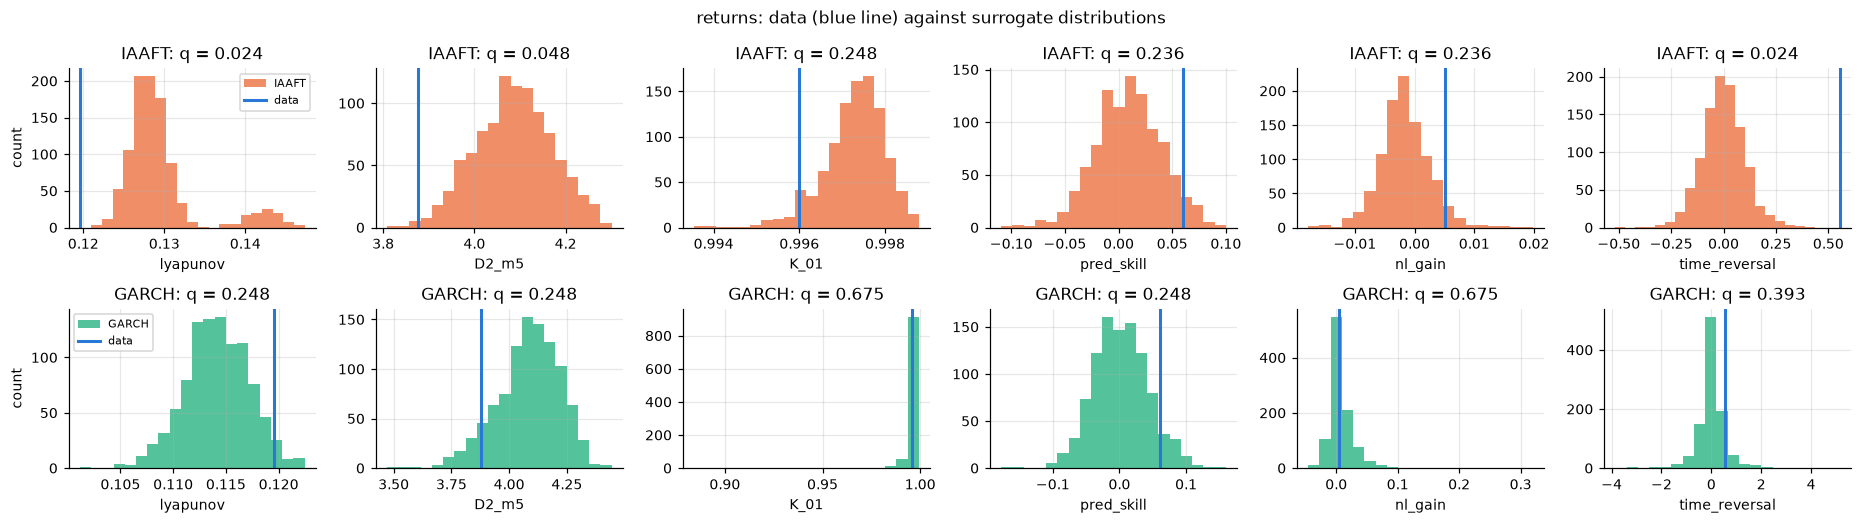

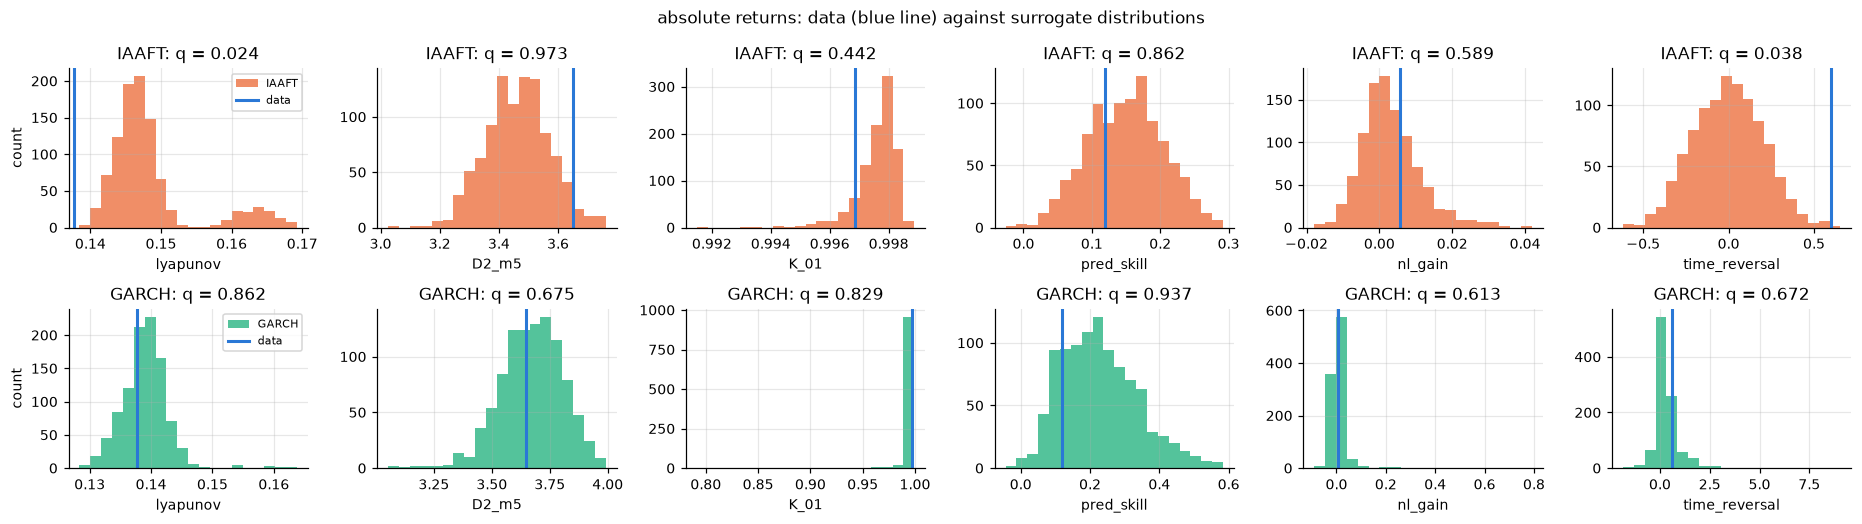

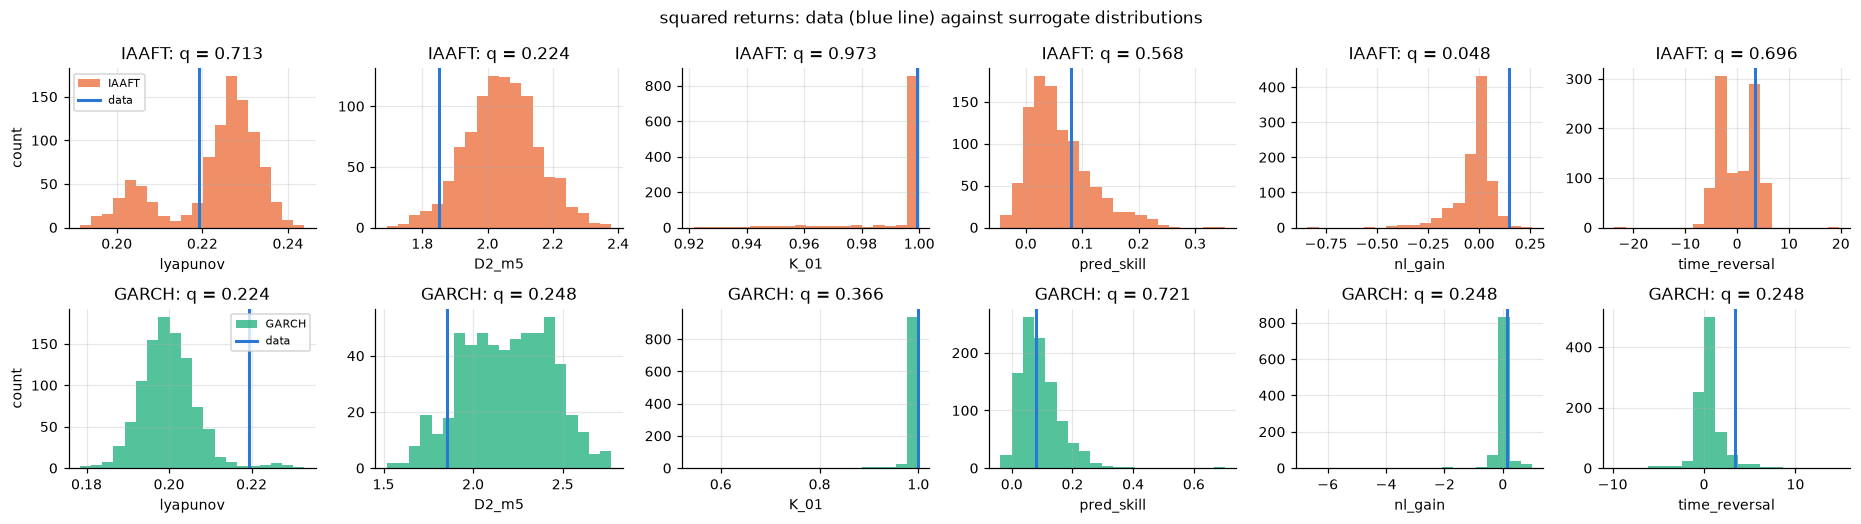

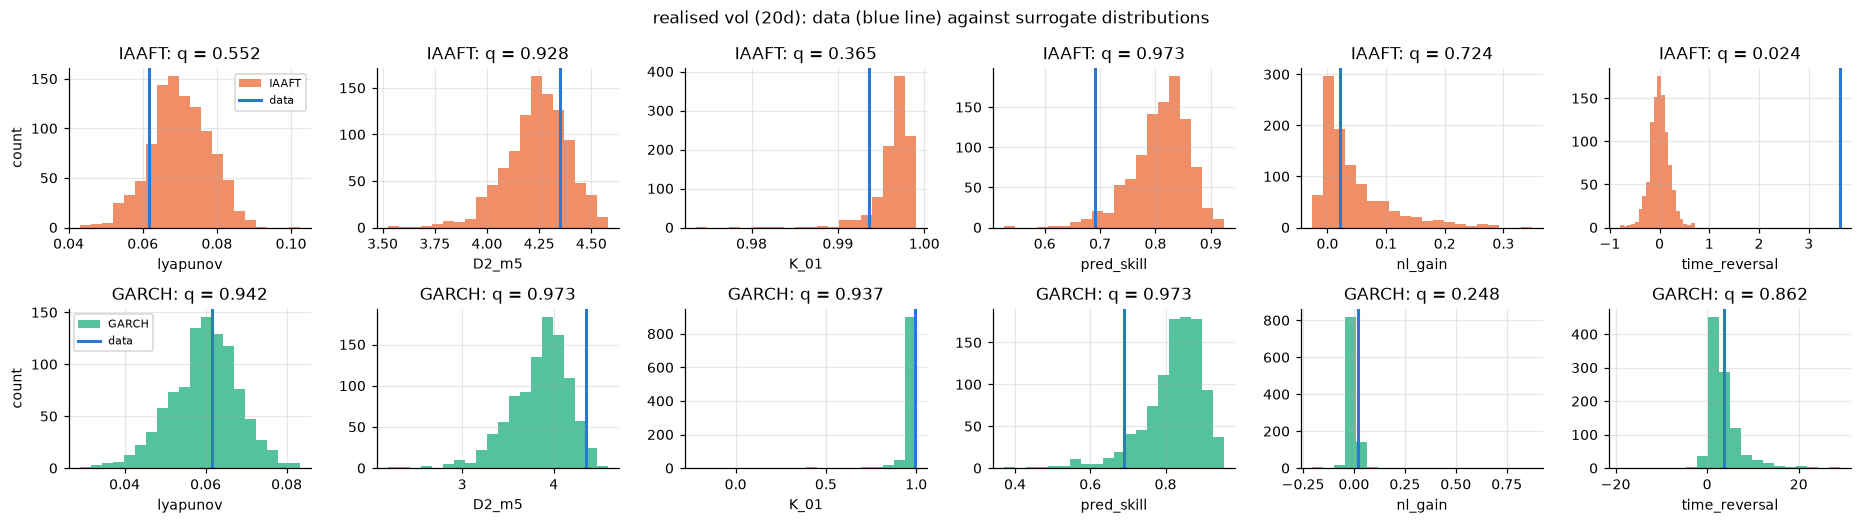

In [14]:
for k in NAMES:
    fig, ax = plt.subplots(2, 6, figsize=(17, 4.8))
    for row, kind in enumerate(["iaaft", "garch"]):
        nd = NULLS[(k, kind)]
        for col, st in enumerate(STATS):
            a = ax[row, col]
            obs = TESTS[(TESTS.series == k) & (TESTS.statistic == st)].iloc[0]["observed"]
            q = TESTS[(TESTS.series == k) & (TESTS.statistic == st) & (TESTS.surrogate == kind.upper())].iloc[0]["q (BH)"]
            a.hist(nd[st].dropna(), bins=20, color=ORANGE if kind == "iaaft" else GREEN, alpha=0.75, label=f"{kind.upper()}")
            a.axvline(obs, color=BLUE, lw=2, label="data")
            a.set(title=f"{kind.upper()}: q = {q:.3f}", xlabel=st, ylabel="count" if col == 0 else None)
            if col == 0: a.legend(fontsize=7)
    fig.suptitle(f"{k}: data (blue line) against surrogate distributions", fontsize=11)
    save(fig, f"09_surrogates_{k.replace(' ', '_').replace('(', '').replace(')', '')}")

## 6. Comparison table and classification

Decision rule (fixed before looking at the results; uses FDR-adjusted q-values):
- **nonlinear**: at least one statistic differs from IAAFT surrogates.
- **beyond GARCH**: at least one statistic differs from GARCH surrogates.
- **Periodic**: K < 0.2 and D2 saturates below 0.5.
- **Quasi-periodic**: K < 0.2 and D2 saturates at 0.5 or more.
- **Potentially Chaotic**: K > 0.8, D2 saturates, and at least two of {D2 lower, prediction skill higher,
  S-map gain higher, Lyapunov different} hold against **both** IAAFT and GARCH surrogates.
- **Random/Stochastic**: K > 0.8 and no statistic differs from the GARCH surrogates (whatever nonlinearity exists
  is reproduced by a stochastic volatility model).
- **Inconclusive**: anything else.

In [15]:
def classify(k, tab):
    d = diag[k]
    sig = lambda fam: tab[(tab.series == k) & (tab.surrogate == fam) & tab.significant]["statistic"].tolist()
    si, sg = sig("IAAFT"), sig("GARCH")
    detdir = [s for s in ["D2_m5", "pred_skill", "nl_gain", "lyapunov"] if s in si and s in sg]
    if d["K"] < 0.2 and d["sat"] and d["d2v"] < 0.5:
        lab = "Periodic"
    elif d["K"] < 0.2 and d["sat"]:
        lab = "Quasi-periodic"
    elif d["K"] > 0.8 and d["sat"] and len(detdir) >= 2:
        lab = "Potentially Chaotic"
    elif d["K"] > 0.8 and not sg:
        lab = "Random/Stochastic"
    else:
        lab = "Inconclusive"
    return si, sg, lab

COMP = []
for k in NAMES:
    e, d = emb[k], diag[k]
    si, sg, lab = classify(k, TESTS)
    zi = TESTS[(TESTS.series == k) & (TESTS.surrogate == "IAAFT")].set_index("statistic")["z"]
    COMP.append({"series": k, "tau": e["tau"], "m (FNN)": f"{e['m']}" + ("" if e["fnn_reached"] else " (not reached)"),
                 "DET": round(DET[k], 3), "Lyapunov": round(d["lle"], 4), "D2": (round(d["d2v"], 2) if d["sat"] else "no saturation"),
                 "K": round(d["K"], 3), "S-map gain": round(TESTS[(TESTS.series == k) & (TESTS.statistic == "nl_gain")].iloc[0]["observed"], 4),
                 "z(S-map gain) vs IAAFT": round(zi["nl_gain"], 2), "z(pred skill) vs IAAFT": round(zi["pred_skill"], 2),
                 "differs from IAAFT": ", ".join(si) or "none", "differs from GARCH": ", ".join(sg) or "none",
                 "nonlinear": "yes" if si else "no", "beyond GARCH": "yes" if sg else "no", "classification": lab})
COMP = pd.DataFrame(COMP)
COMP.to_csv(FIG / "comparison_table.csv", index=False)
COMP.T

,0,1,2,3
series,returns,absolute returns,squared returns,realised vol (20d)
tau,1,1,1,22
m (FNN),10 (not reached),10 (not reached),10 (not reached),10 (not reached)
DET,0.963,0.965,0.966,0.908
Lyapunov,0.1196,0.1377,0.2193,0.0616
D2,4.14,3.76,2.55,5.22
K,0.998,0.997,0.999,0.994
S-map gain,0.0052,0.0056,0.1457,0.0208
z(S-map gain) vs IAAFT,1.6,0.29,1.86,-0.4
z(pred skill) vs IAAFT,1.67,-0.55,0.37,-2.27


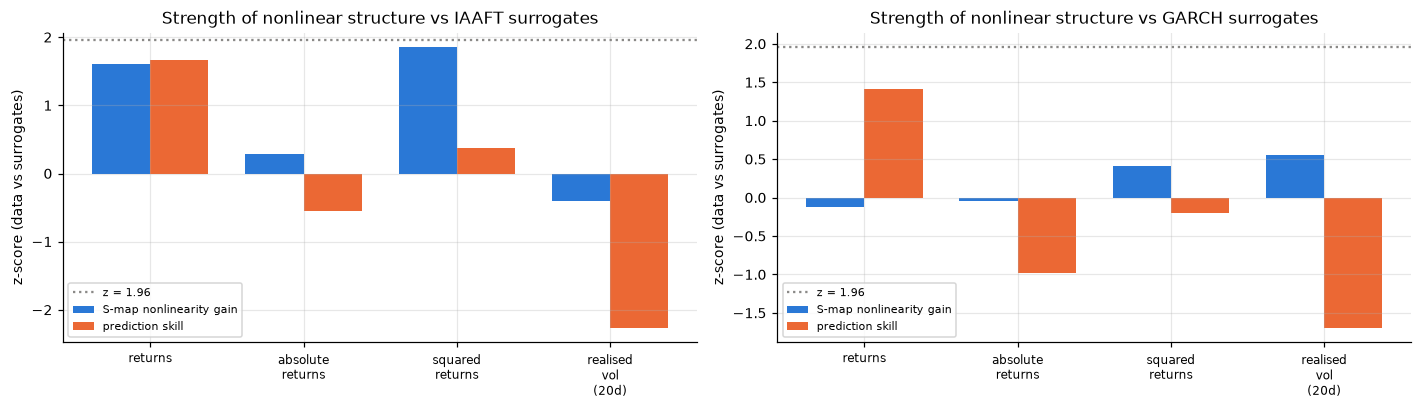

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
w = 0.38
for j, fam in enumerate(["IAAFT", "GARCH"]):
    zz = [TESTS[(TESTS.series == k) & (TESTS.surrogate == fam) & (TESTS.statistic == "nl_gain")].iloc[0]["z"] for k in NAMES]
    zp = [TESTS[(TESTS.series == k) & (TESTS.surrogate == fam) & (TESTS.statistic == "pred_skill")].iloc[0]["z"] for k in NAMES]
    ax[j].bar(np.arange(4) - w / 2, zz, w, color=BLUE, label="S-map nonlinearity gain")
    ax[j].bar(np.arange(4) + w / 2, zp, w, color=ORANGE, label="prediction skill")
    ax[j].axhline(1.96, color=GREY, ls=":", label="z = 1.96")
    ax[j].set_xticks(range(4)); ax[j].set_xticklabels([n.replace(" ", "\n") for n in NAMES], fontsize=8)
    ax[j].set(title=f"Strength of nonlinear structure vs {fam} surrogates", ylabel="z-score (data vs surrogates)")
    ax[j].legend(fontsize=7)
save(fig, "10_nonlinearity_strength")

## 7. Robustness to non-stationarity: split-sample check

BTC's volatility level changed a lot between 2017-2021 and 2022-2026. Surrogate rejections caused only by a
change of regime would not appear consistently in both halves. The full test (GARCH refitted on each half,
499 surrogates per family) is repeated on each half; FDR is applied within each half.

In [17]:
half = len(r_used) // 2
t0 = time.time()
H1, _, _ = run_tests(r_used[:half], N_SURR_HALF, SEED + 1, "first half")
H2, _, _ = run_tests(r_used[half:], N_SURR_HALF, SEED + 2, "second half")
print(f"split-sample tests: {time.time() - t0:.0f} s;  first half ends {r_full.index[half - 1].date()}")
split = []
for k in NAMES:
    row = {"series": k}
    for lab, tab in [("full", TESTS), ("1st half", H1), ("2nd half", H2)]:
        si, sg, cl = classify(k, tab) if lab == "full" else (
            tab[(tab.series == k) & (tab.surrogate == "IAAFT") & tab.significant]["statistic"].tolist(),
            tab[(tab.series == k) & (tab.surrogate == "GARCH") & tab.significant]["statistic"].tolist(), None)
        row[f"{lab}: vs IAAFT"] = ", ".join(si) or "none"
        row[f"{lab}: vs GARCH"] = ", ".join(sg) or "none"
    split.append(row)
SPLIT = pd.DataFrame(split)
SPLIT.T

split-sample tests: 1367 s;  first half ends 2022-02-23


,0,1,2,3
series,returns,absolute returns,squared returns,realised vol (20d)
full: vs IAAFT,"lyapunov, D2_m5, time_reversal","lyapunov, time_reversal",nl_gain,time_reversal
full: vs GARCH,none,none,none,none
1st half: vs IAAFT,D2_m5,time_reversal,D2_m5,time_reversal
1st half: vs GARCH,none,none,none,none
2nd half: vs IAAFT,none,none,none,none
2nd half: vs GARCH,none,none,none,none


Note: the split-sample check reuses the full-sample embedding (tau, m) and the full-sample 0-1 test is not part of
it; it only checks whether surrogate rejections are stable over time.

## 8. Research summary (generated from the results above)

In [18]:
def summary():
    out = []
    nonlin = [k for k in NAMES if COMP.set_index("series").loc[k, "nonlinear"] == "yes"]
    beyond = [k for k in NAMES if COMP.set_index("series").loc[k, "beyond GARCH"] == "yes"]
    out.append(f"Sample: BTC daily, {dates[0].date()} to {dates[-1].date()} (n = {len(dates)}).")
    out.append("")
    out.append("1. Nonlinear dependence. Series that differ from IAAFT (linear) surrogates after FDR: "
               + (", ".join(nonlin) if nonlin else "none") + ".")
    zi = COMP.set_index("series")
    out.append("   S-map nonlinearity gain z-scores vs IAAFT: " + "; ".join(f"{k} {zi.loc[k, 'z(S-map gain) vs IAAFT']}" for k in NAMES) + ".")
    out.append("2. GARCH explanation. Series with any statistic beyond GARCH(1,1)-t surrogates after FDR: "
               + (", ".join(f"{k} ({zi.loc[k, 'differs from GARCH']})" for k in beyond) if beyond else "none") + ".")
    chaotic = [k for k in NAMES if zi.loc[k, "classification"] == "Potentially Chaotic"]
    out.append("3. Deterministic chaos. " + ("Series meeting the potentially-chaotic rule: " + ", ".join(chaotic) + "."
               if chaotic else "No series meets the rule for potentially chaotic dynamics. Positive Lyapunov exponents and K near 1 "
               "occur for the surrogates as well, so they are not evidence of chaos."))
    out.append("4. Classification: " + "; ".join(f"{k}: {zi.loc[k, 'classification']}" for k in NAMES) + ".")
    stable = [k for k in beyond if SPLIT.set_index("series").loc[k, "1st half: vs GARCH"] != "none"
              and SPLIT.set_index("series").loc[k, "2nd half: vs GARCH"] != "none"]
    out.append("5. Stability over time: series beyond GARCH in both halves: " + (", ".join(stable) if stable else "none") + ".")
    return "\n".join(out)
print(summary())

Sample: BTC daily, 2017-09-06 to 2026-09-02 (n = 3284).

1. Nonlinear dependence. Series that differ from IAAFT (linear) surrogates after FDR: returns, absolute returns, squared returns, realised vol (20d).
   S-map nonlinearity gain z-scores vs IAAFT: returns 1.6; absolute returns 0.29; squared returns 1.86; realised vol (20d) -0.4.
2. GARCH explanation. Series with any statistic beyond GARCH(1,1)-t surrogates after FDR: none.
3. Deterministic chaos. No series meets the rule for potentially chaotic dynamics. Positive Lyapunov exponents and K near 1 occur for the surrogates as well, so they are not evidence of chaos.
4. Classification: returns: Random/Stochastic; absolute returns: Random/Stochastic; squared returns: Random/Stochastic; realised vol (20d): Random/Stochastic.
5. Stability over time: series beyond GARCH in both halves: none.


## 9. Research interpretation (written for the run on BTC daily, 2017-09-06 to 2026-09-02)

**Does volatility contain nonlinear dependence?** Yes, and so do returns. All four series differ from their
IAAFT (linear) surrogates after FDR control. The strongest single signal is the **time-reversal asymmetry of
20-day realised volatility** (z = 18.6): volatility jumps up quickly and decays slowly, which no linear Gaussian
process can do. Returns show asymmetry as well (z = 5.4), and absolute returns somewhat less (z = 2.9).

**Is volatility more nonlinear than returns?** Only in one respect. Realised volatility has by far the largest
asymmetry, but it is not more predictable by a nonlinear model: its S-map gain and prediction skill are not
above the surrogates (z = -0.4 and -2.3). Squared returns have the largest S-map gain (0.146), but heavy-tailed
surrogates reach similar values (z = 1.9, q = 0.048 against IAAFT, not significant against GARCH).

**Can GARCH explain it?** Yes, completely. No statistic of any series differs from GARCH(1,1)-t surrogates
(smallest q = 0.22). For realised volatility the asymmetry against GARCH is z = 0.01: a GARCH process produces
exactly the same rise-fast, decay-slow pattern.

**Is there convincing evidence of deterministic chaos?** No. FNN never falls below 5% (all series need more
than 10 dimensions), the correlation dimension levels off only at 2.6 to 5.2, at the same levels as noise
surrogates, every series has K near 1 and a positive Lyapunov exponent, and the GARCH surrogates match both.
All four series are classified **Random/Stochastic**: nonlinear, but stochastic.

**Non-stationarity.** The IAAFT rejections come mainly from the first half (2017-09 to 2022-02). In the
second half (2022-02 to 2026-09) no series differs even from IAAFT. Part of the measured nonlinearity is
therefore tied to the turbulent early regime, which is consistent with volatility clustering and regime
changes, not with a stable deterministic attractor.

**What deserves further investigation.** Realised volatility. It carries the clearest nonlinear signature
(asymmetry), and the next step is a richer stochastic null that it might beat: an asymmetric GARCH
(GJR or EGARCH), a long-memory model (FIGARCH or HAR), or a regime-switching model. If realised volatility still
matched those surrogates, the case for stochastic volatility would be stronger; if it did not, that would be a
specific nonlinearity to model, still not evidence of chaos on its own.

## 10. Power Spectrum Analysis

The frequency domain asks three different questions, which must not be confused:

| Signature in the spectrum | What it would mean | What it does **not** mean |
|---|---|---|
| sharp peak at a frequency $f_0$ | a periodic or seasonal component with period $1/f_0$ days | chaos |
| power law $S(f) \propto f^{-\beta}$ at low frequencies, $\beta > 0$ | long memory / scaling (slowly decaying autocorrelation) | chaos: fractional noise and GARCH can produce it |
| broadband spectrum with no peaks | irregular dynamics: noise **or** chaos | either one in particular |

Settings (fixed before computing anything):
- every series is standardised (mean 0, variance 1) and linearly detrended, so the four spectra are comparable;
- Welch: Hann window, 512-day segments, 50% overlap (frequency resolution 1/512 cycles per day);
  periodogram: whole sample, rectangular window, for comparison;
- frequency in cycles per day (Nyquist 0.5); period = 1 / frequency in days;
- spectral slope fitted on the Welch PSD over periods 25 to 250 days ($f$ from 0.004 to 0.04). Below 25 days
  the 20-day realised-volatility window filters the spectrum by construction; above 250 days there are fewer than
  two cycles per Welch segment. A second estimator, the Geweke Porter-Hudak (GPH) log-periodogram regression over
  the lowest $\sqrt{n} \approx 57$ Fourier frequencies (periods above 57 days), gives $\beta = 2d$;
- low band: periods above 20 days; high band: periods below 5 days;
- 999 IAAFT and 999 GARCH surrogates per series, Welch spectra computed identically. Note: IAAFT surrogates keep
  the power spectrum **by construction**, so the IAAFT comparison is a consistency check, not a test. The GARCH
  comparison is the informative one.

In [19]:
from scipy import stats as sst
PSD_DIR = FIG / "power_spectrum"; PSD_DIR.mkdir(parents=True, exist_ok=True)

def save_psd(fig, name):
    fig.tight_layout()
    fig.savefig(PSD_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

COLS = dict(zip(NAMES, [BLUE, ORANGE, GREEN, "#6250d6"]))
SPEC = {}
for k in NAMES:
    f, P = T.psd_welch(S[k])
    fp, Pp = T.psd_periodogram(S[k])
    SPEC[k] = {"f": f, "P": P, "fp": fp, "Pp": Pp}

t0 = time.time()
SURR_PSD = {k: T.surrogate_spectra(make_series, r_used, k, GARCH, N_SURR, SEED) for k in NAMES}
print(f"surrogate spectra: {time.time() - t0:.0f} s  ({N_SURR} per family and series)")
print(f"Note: fitted GARCH persistence alpha + beta = {GARCH.params['alpha[1]'] + GARCH.params['beta[1]']:.4f}")

surrogate spectra: 157 s  (999 per family and series)
Note: fitted GARCH persistence alpha + beta = 1.0000


### 10.1 PSD against frequency (linear axes): Welch and periodogram

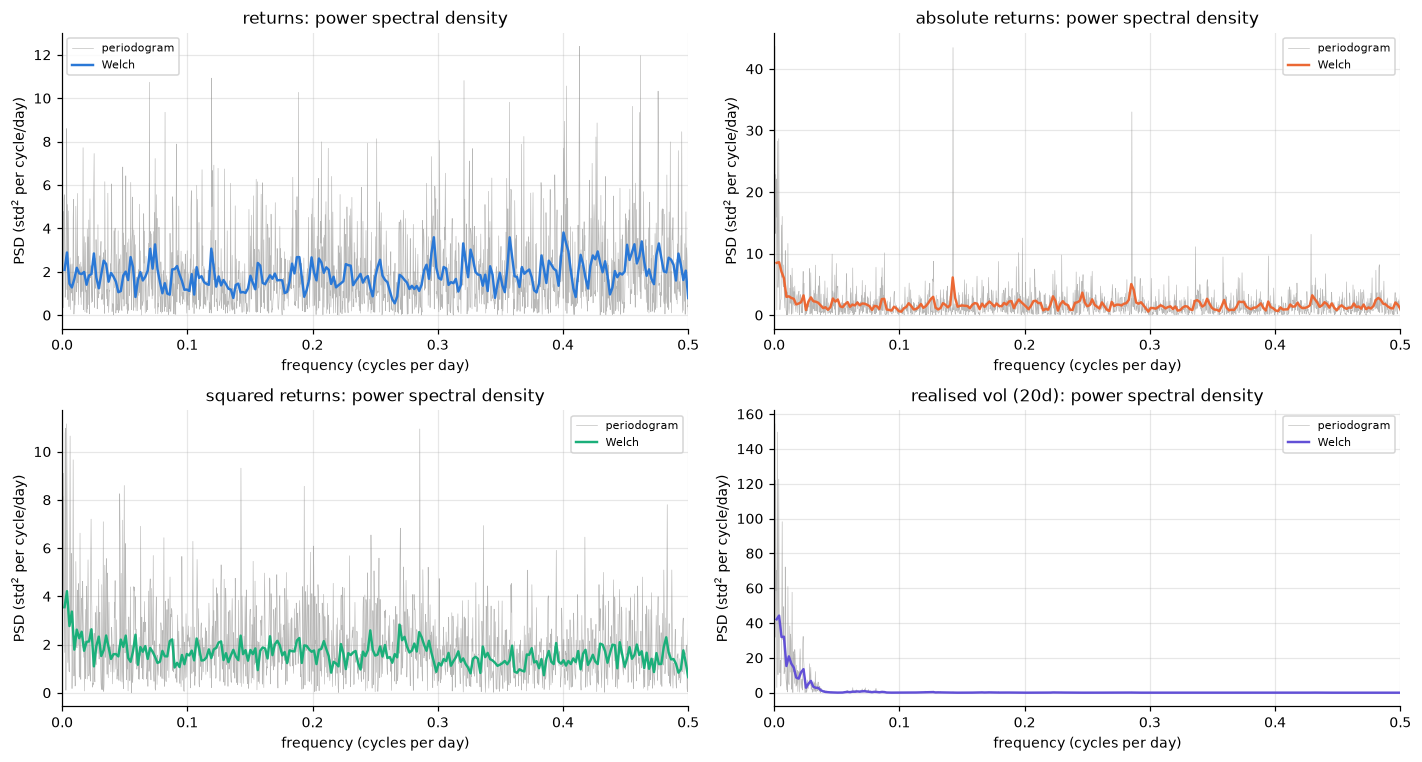

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, k in zip(ax.flat, NAMES):
    s = SPEC[k]
    a.plot(s["fp"], s["Pp"], lw=0.4, color=GREY, alpha=0.6, label="periodogram")
    a.plot(s["f"], s["P"], lw=1.6, color=COLS[k], label="Welch")
    a.set(title=f"{k}: power spectral density", xlabel="frequency (cycles per day)",
          ylabel="PSD (std$^2$ per cycle/day)", xlim=(0, 0.5))
    a.legend(fontsize=7)
save_psd(fig, "01_psd_vs_frequency")

### 10.2 PSD against period (days)

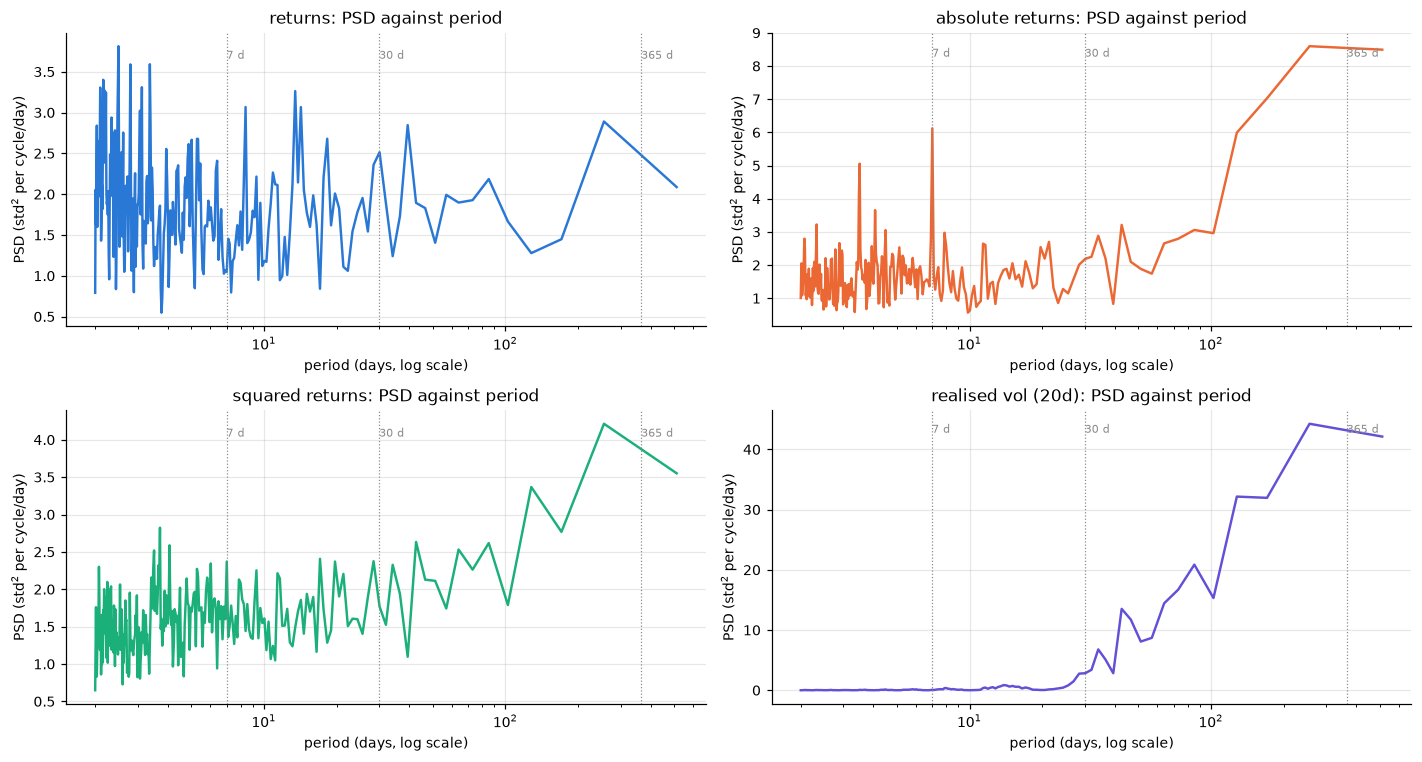

In [21]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, k in zip(ax.flat, NAMES):
    s = SPEC[k]
    a.semilogx(1 / s["f"], s["P"], lw=1.6, color=COLS[k])
    for d_, lab in [(7, "7 d"), (30, "30 d"), (365, "365 d")]:
        a.axvline(d_, color=GREY, ls=":", lw=0.8); a.text(d_, a.get_ylim()[1] * 0.92, lab, fontsize=7, color=GREY)
    a.set(title=f"{k}: PSD against period", xlabel="period (days, log scale)", ylabel="PSD (std$^2$ per cycle/day)")
save_psd(fig, "02_psd_vs_period")

### 10.3 Log-log spectra with the power-law fit

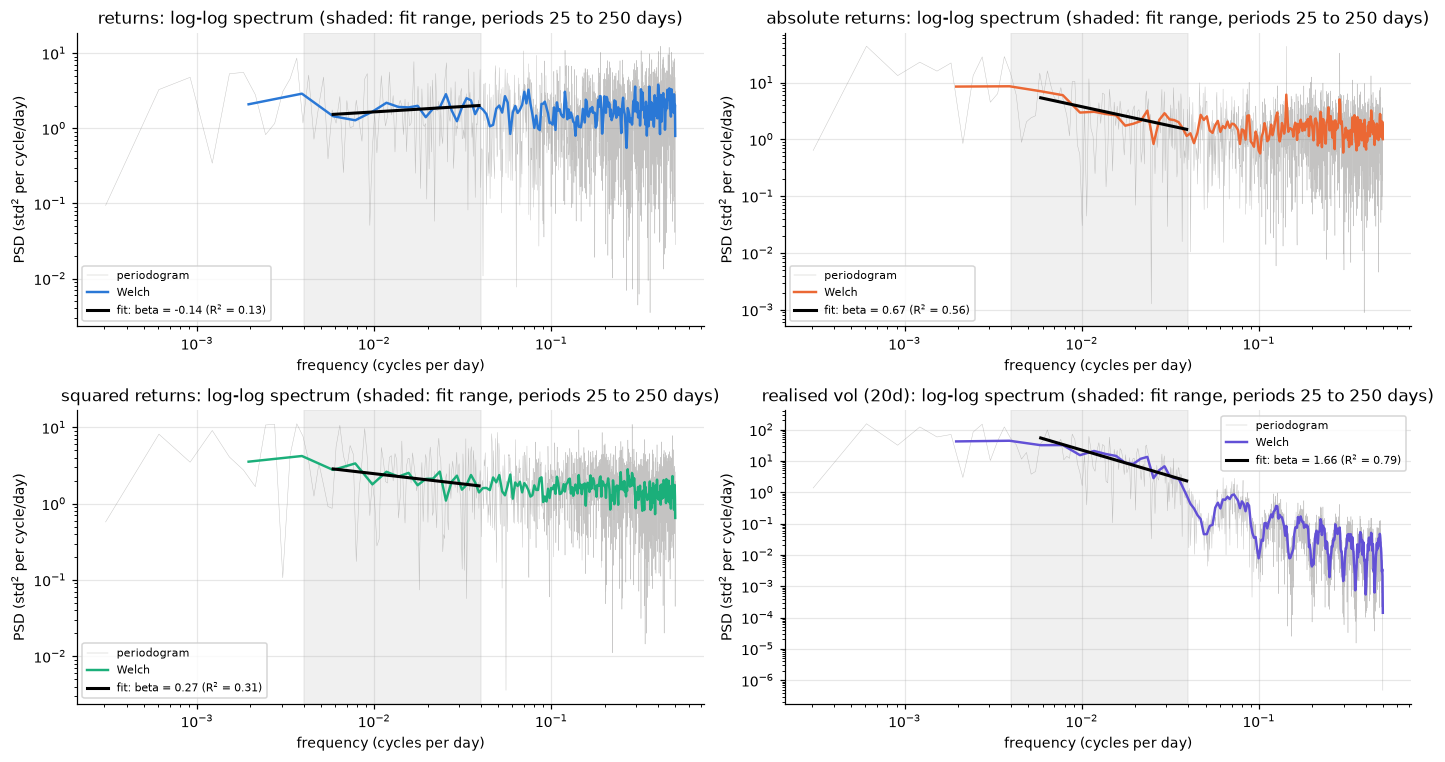

In [22]:
SLOPES = {}
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, k in zip(ax.flat, NAMES):
    s = SPEC[k]
    beta, se, r2, npts = T.spectral_slope(s["f"], s["P"])
    d, d_se, m_gph, beta_gph = T.gph(S[k])
    SLOPES[k] = {"beta": beta, "se": se, "r2": r2, "n": npts, "d": d, "d_se": d_se, "m_gph": m_gph, "beta_gph": beta_gph}
    a.loglog(s["fp"], s["Pp"], lw=0.3, color=GREY, alpha=0.5, label="periodogram")
    a.loglog(s["f"], s["P"], lw=1.6, color=COLS[k], label="Welch")
    sel = (s["f"] >= T.SLOPE_RANGE[0]) & (s["f"] <= T.SLOPE_RANGE[1])
    c = np.mean(np.log10(s["P"][sel]) + beta * np.log10(s["f"][sel]))
    ff = s["f"][sel]
    a.loglog(ff, 10 ** c * ff ** (-beta), color="black", lw=2, label=f"fit: beta = {beta:.2f} (R$^2$ = {r2:.2f})")
    a.axvspan(*T.SLOPE_RANGE, color=GREY, alpha=0.12)
    a.set(title=f"{k}: log-log spectrum (shaded: fit range, periods 25 to 250 days)",
          xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)")
    a.legend(fontsize=7)
save_psd(fig, "03_loglog_spectrum")

### 10.4 All four spectra in one figure

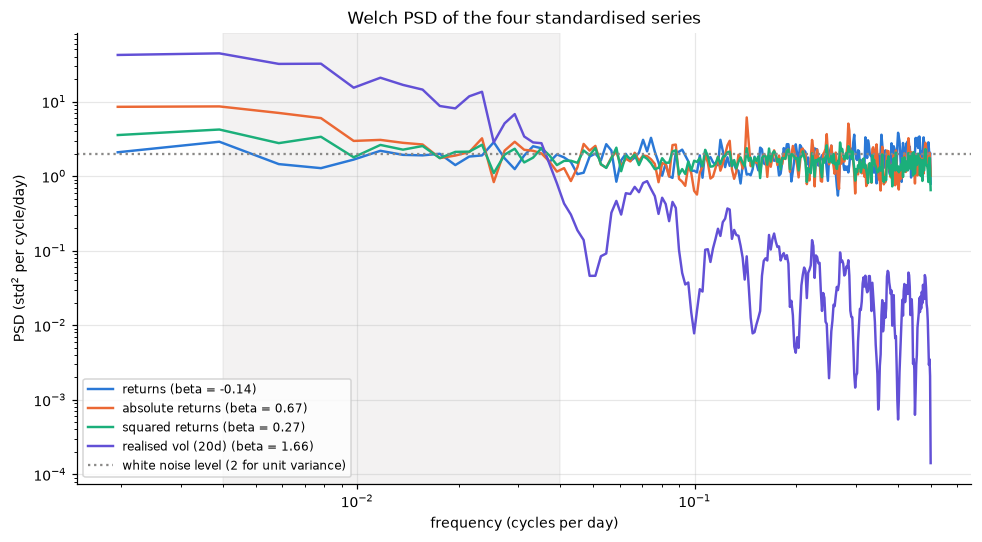

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
for k in NAMES:
    ax.loglog(SPEC[k]["f"], SPEC[k]["P"], lw=1.6, color=COLS[k], label=f"{k} (beta = {SLOPES[k]['beta']:.2f})")
ax.axhline(2.0, color=GREY, ls=":", label="white noise level (2 for unit variance)")
ax.axvspan(*T.SLOPE_RANGE, color=GREY, alpha=0.1)
ax.set(title="Welch PSD of the four standardised series", xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)")
ax.legend(fontsize=8)
save_psd(fig, "04_psd_comparison")

### 10.5 Data against IAAFT and GARCH surrogate spectra
Lines: data (colour) and surrogate median (black); band: pointwise 2.5% to 97.5% of the 999 surrogate spectra.

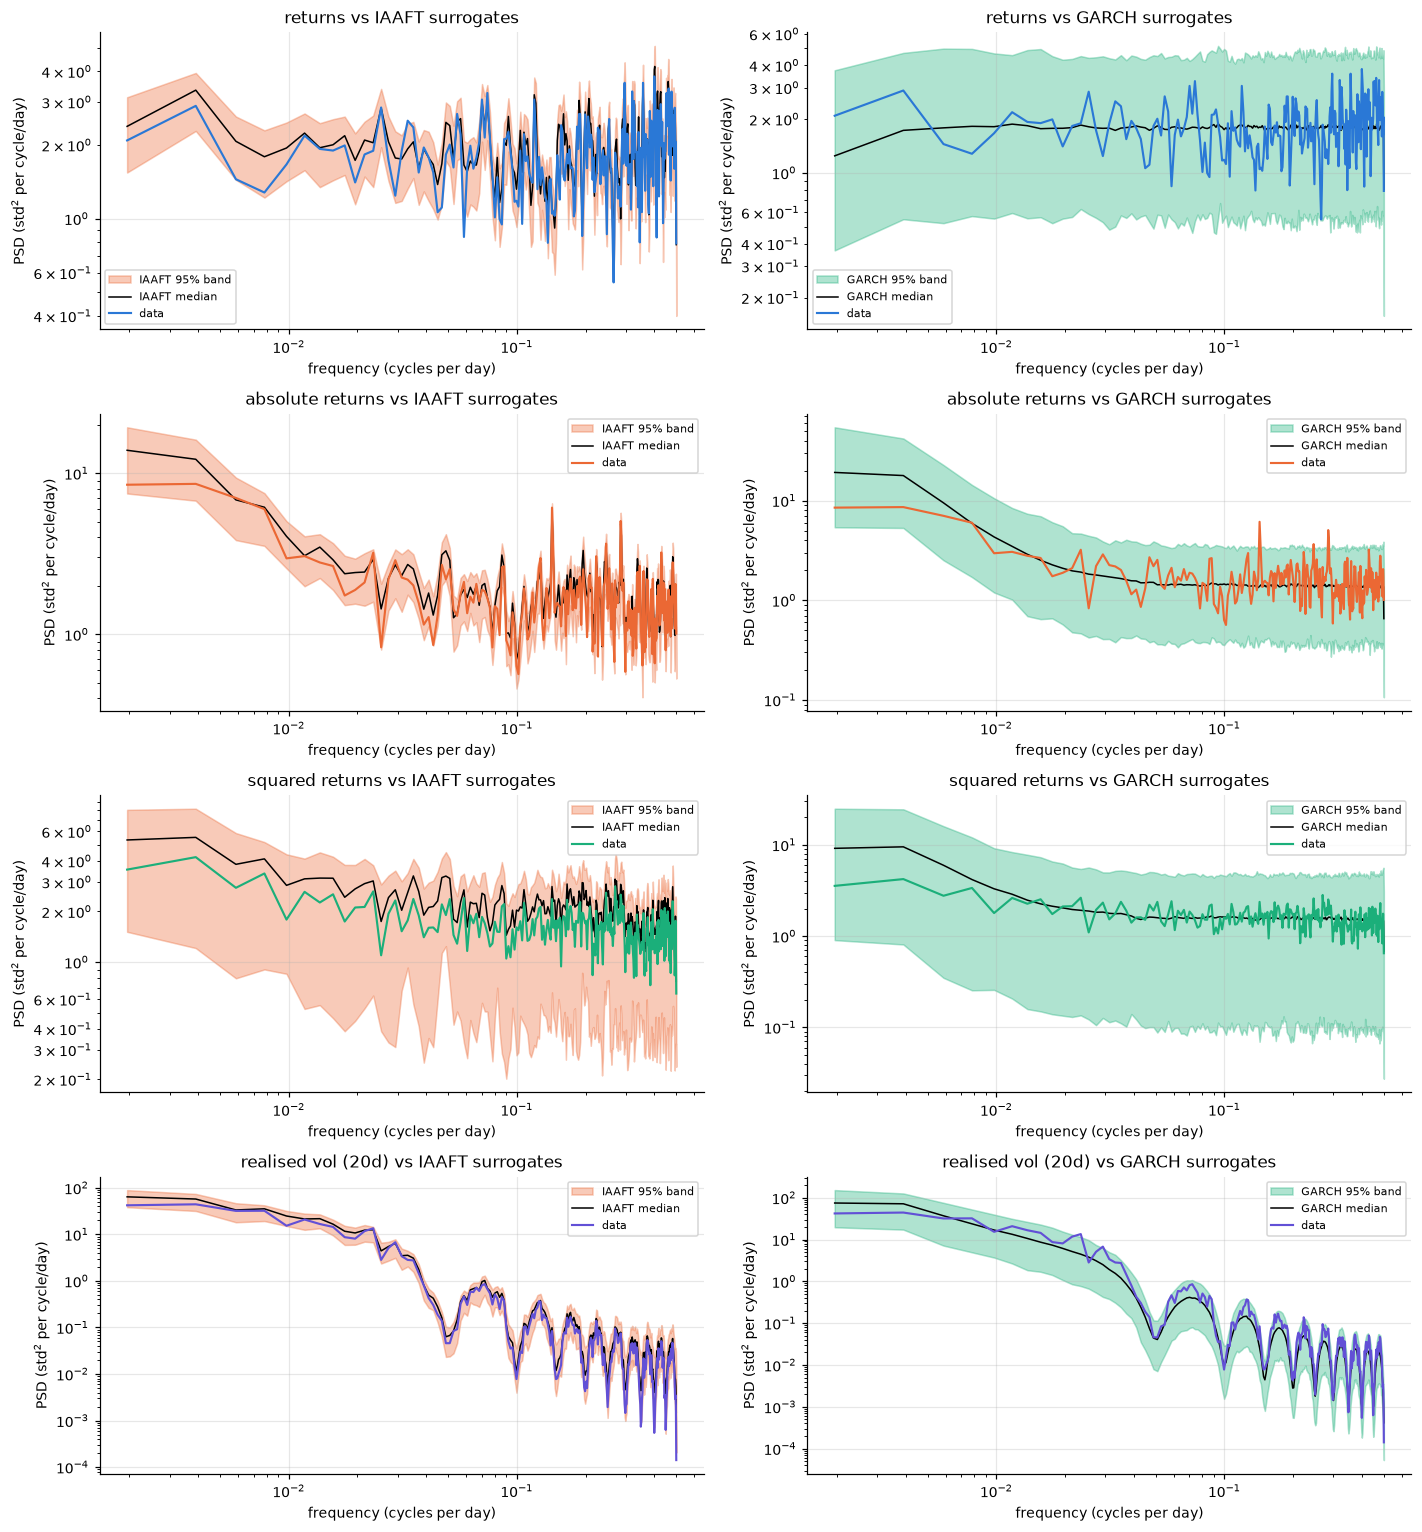

In [24]:
fig, ax = plt.subplots(4, 2, figsize=(13, 14))
for i, k in enumerate(NAMES):
    for j, kind in enumerate(["iaaft", "garch"]):
        a = ax[i, j]
        Pn = SURR_PSD[k][kind]["P"]
        lo, med, hi = np.quantile(Pn, [0.025, 0.5, 0.975], axis=0)
        a.fill_between(SPEC[k]["f"], lo, hi, color=ORANGE if kind == "iaaft" else GREEN, alpha=0.35, label=f"{kind.upper()} 95% band")
        a.loglog(SPEC[k]["f"], med, color="black", lw=1, label=f"{kind.upper()} median")
        a.loglog(SPEC[k]["f"], SPEC[k]["P"], color=COLS[k], lw=1.4, label="data")
        a.set(title=f"{k} vs {kind.upper()} surrogates", xlabel="frequency (cycles per day)", ylabel="PSD (std$^2$ per cycle/day)")
        a.legend(fontsize=7)
save_psd(fig, "05_surrogate_spectra")

### 10.6 Statistics: peaks, weekly component, band powers, scaling exponent, surrogate tests

- **Peaks**: the three largest local maxima of the Welch PSD. A peak counts as a periodic component only if its
  power is above the GARCH 97.5% band at that frequency **and** the whole spectrum fails the global test.
- **Weekly component** (crypto trades 7 days a week): Welch PSD at the frequency bin nearest 1/7 cycles per day
  against the GARCH surrogates (one-sided).
- **Global test**: maximum standardised deviation of the log spectrum from the surrogate median over all
  frequencies, compared with the same statistic for every surrogate.
- p-values for beta and band shares are two-sided rank p-values against the GARCH surrogates.
- Benjamini-Hochberg FDR across all GARCH tests in the table (4 series x 4 tests).

In [25]:
rows = []
for k in NAMES:
    s, sl = SPEC[k], SLOPES[k]
    lo_sh, hi_sh = T.band_shares(s["f"], s["P"])
    g = SURR_PSD[k]["garch"]; ia = SURR_PSD[k]["iaaft"]
    p_glob_g, D_g, out_g = T.envelope_test(s["P"], g["P"])
    p_glob_i, D_i, out_i = T.envelope_test(s["P"], ia["P"])
    iw = int(np.argmin(np.abs(s["f"] - 1 / 7)))
    p_week = T.p_value(s["P"][iw], g["P"][:, iw], "greater")
    peaks = T.spectral_peaks(s["f"], s["P"])
    hi97 = np.quantile(g["P"], 0.975, axis=0)
    peak_txt = "; ".join(f"{per:.1f} d" + (" (above GARCH band)" if P_ > hi97[np.argmin(np.abs(s['f'] - fr))] else "")
                         for fr, per, P_ in peaks)
    rows.append({"series": k,
                 "beta (Welch, 25-250 d)": round(sl["beta"], 3), "s.e.": round(sl["se"], 3), "R^2": round(sl["r2"], 3),
                 "points": sl["n"],
                 "beta GARCH median [95%]": f"{np.median(g['beta']):.2f} [{np.quantile(g['beta'], 0.025):.2f}, {np.quantile(g['beta'], 0.975):.2f}]",
                 "p beta vs GARCH": T.p_value(sl["beta"], g["beta"], "two-sided"),
                 "beta GPH = 2d (s.e.)": f"{sl['beta_gph']:.2f} ({2 * sl['d_se']:.2f})",
                 "low-band share (>20 d)": round(lo_sh, 3),
                 "low share GARCH median": round(float(np.median(g["low"])), 3),
                 "p low share vs GARCH": T.p_value(lo_sh, g["low"], "two-sided"),
                 "high-band share (<5 d)": round(hi_sh, 3),
                 "top peaks (period)": peak_txt,
                 "p weekly (7 d) vs GARCH": p_week,
                 "global p vs GARCH": p_glob_g, "outside GARCH band": round(out_g, 3),
                 "global p vs IAAFT": p_glob_i, "outside IAAFT band": round(out_i, 3)})
PSD_TAB = pd.DataFrame(rows)
garch_p = ["p beta vs GARCH", "p low share vs GARCH", "p weekly (7 d) vs GARCH", "global p vs GARCH"]
qs = T.bh(PSD_TAB[garch_p].values.ravel()).reshape(len(NAMES), len(garch_p))
for j, c in enumerate(garch_p):
    PSD_TAB[c.replace("p ", "q ", 1) if c.startswith("p ") else "q " + c] = qs[:, j]
PSD_TAB.to_csv(PSD_DIR / "power_spectrum_summary.csv", index=False)
PSD_TAB.set_index("series").T

series,returns,absolute returns,squared returns,realised vol (20d)
"beta (Welch, 25-250 d)",-0.143,0.674,0.269,1.663
s.e.,0.093,0.149,0.1,0.216
R^2,0.128,0.561,0.309,0.788
points,18,18,18,18
beta GARCH median [95%],"0.00 [-0.60, 0.71]","0.85 [0.32, 1.57]","0.57 [-0.16, 1.59]","1.96 [1.42, 2.65]"
p beta vs GARCH,0.594,0.52,0.396,0.25
beta GPH = 2d (s.e.),0.01 (0.17),1.14 (0.17),0.50 (0.17),0.98 (0.17)
low-band share (>20 d),0.092,0.156,0.127,0.936
low share GARCH median,0.092,0.2,0.143,0.958
p low share vs GARCH,0.988,0.124,0.46,0.068


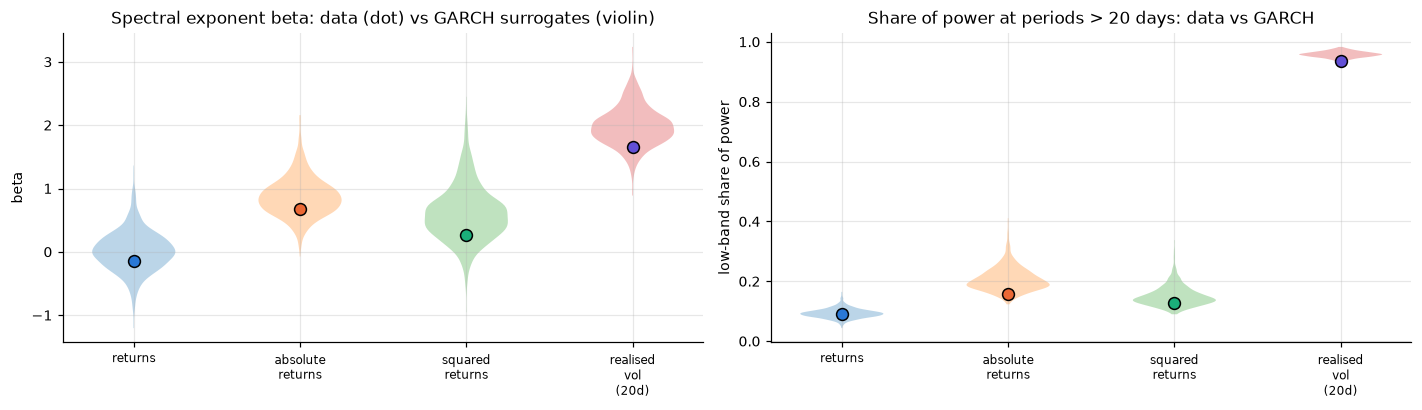

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, k in enumerate(NAMES):
    g = SURR_PSD[k]["garch"]["beta"]
    ax[0].violinplot(g, positions=[i], showextrema=False)
    ax[0].scatter(i, SLOPES[k]["beta"], color=COLS[k], s=60, zorder=3, edgecolor="black")
    gl = SURR_PSD[k]["garch"]["low"]
    ax[1].violinplot(gl, positions=[i], showextrema=False)
    ax[1].scatter(i, T.band_shares(SPEC[k]["f"], SPEC[k]["P"])[0], color=COLS[k], s=60, zorder=3, edgecolor="black")
for a, t, yl in [(ax[0], "Spectral exponent beta: data (dot) vs GARCH surrogates (violin)", "beta"),
                 (ax[1], "Share of power at periods > 20 days: data vs GARCH", "low-band share of power")]:
    a.set_xticks(range(4)); a.set_xticklabels([n.replace(" ", "\n") for n in NAMES], fontsize=8)
    a.set(title=t, ylabel=yl)
save_psd(fig, "06_beta_and_lowband_vs_garch")

### 10.7 Power spectrum summary (generated from the results above)

In [27]:
def psd_summary():
    t = PSD_TAB.set_index("series")
    sig = lambda c, k: t.loc[k, c] < ALPHA
    lines = []
    r_ = "returns"
    lines.append(f"Periodicity in returns: global test vs GARCH q = {t.loc[r_, 'q global p vs GARCH']:.3f}; "
                 f"weekly component q = {t.loc[r_, 'q weekly (7 d) vs GARCH']:.3f}; returns spectrum slope beta = {t.loc[r_, 'beta (Welch, 25-250 d)']:.2f} "
                 f"(R^2 = {t.loc[r_, 'R^2']:.2f}). " + ("No periodic component survives." if not (sig('q global p vs GARCH', r_) or sig('q weekly (7 d) vs GARCH', r_)) else "Some spectral structure survives; see table."))
    lines.append("Low-frequency power (share of power at periods > 20 days): " + "; ".join(f"{k} {t.loc[k, 'low-band share (>20 d)']:.2f}" for k in NAMES)
                 + " (white noise: about 0.10).")
    lines.append("Spectral exponent beta (Welch, periods 25-250 days): " + "; ".join(f"{k} {t.loc[k, 'beta (Welch, 25-250 d)']:.2f} (R^2 {t.loc[k, 'R^2']:.2f})" for k in NAMES)
                 + ". GPH: " + "; ".join(f"{k} {t.loc[k, 'beta GPH = 2d (s.e.)']}" for k in NAMES) + ".")
    beyond = [k for k in NAMES if any(sig(c, k) for c in ["q beta vs GARCH", "q low share vs GARCH", "q weekly (7 d) vs GARCH", "q global p vs GARCH"])]
    lines.append("Spectral features beyond GARCH after FDR: " + (", ".join(beyond) if beyond else "none") + ".")
    return "\n".join(lines)
print(psd_summary())

Periodicity in returns: global test vs GARCH q = 0.837; weekly component q = 0.983; returns spectrum slope beta = -0.14 (R^2 = 0.13). No periodic component survives.
Low-frequency power (share of power at periods > 20 days): returns 0.09; absolute returns 0.16; squared returns 0.13; realised vol (20d) 0.94 (white noise: about 0.10).
Spectral exponent beta (Welch, periods 25-250 days): returns -0.14 (R^2 0.13); absolute returns 0.67 (R^2 0.56); squared returns 0.27 (R^2 0.31); realised vol (20d) 1.66 (R^2 0.79). GPH: returns 0.01 (0.17); absolute returns 1.14 (0.17); squared returns 0.50 (0.17); realised vol (20d) 0.98 (0.17).
Spectral features beyond GARCH after FDR: absolute returns, realised vol (20d).


## 11. Time-Domain and Power-Spectrum Regime Analysis

The full sample mixes very different market periods. Here the four series are cut into four periods and
shown period by period in the time domain (time-series panels on common axes) and in the frequency domain
(Welch spectra on a logarithmic axis, offset vertically so the curves do not overlap).

| Period | Dates | Context |
|---|---|---|
| P1 | 2017-09-06 to 2019-12-31 | 2017 bubble, 2018 crash, 2019 recovery |
| P2 | 2020-01-01 to 2021-12-31 | COVID crash, 2020-21 bull market |
| P3 | 2022-01-01 to 2023-12-31 | LUNA and FTX collapses, bear market |
| P4 | 2024-01-01 to 2026-09-02 | spot ETF era |

Settings for this section (fixed before computing):
- The series are those of section 1, computed on the full sample and then cut (realised volatility at the start of
  a period uses the 19 days before it).
- Welch: Hann window, 256-day segments, 50% overlap (each period has 730 to 975 days, so 4 to 6 segments);
  periodogram for comparison. Frequency in cycles per day.
- Figure-5-style spectra show the **actual PSD in the series' own units** (not standardised), so level changes
  between periods remain visible. For display only, the curve of period Pk is multiplied by $10^{(k-1)s}$, where the
  step s (decades) is one more than the largest log range of any curve of that series; the factors are shown in the
  legend and caption, and the unscaled values are saved to csv.
- Surrogate tests use the standardised spectra (shape, not level): 499 IAAFT and 499 GARCH(1,1)-t surrogates per
  period and series; GARCH is refitted on each period's returns and its simulated returns are transformed exactly
  like the data. Statistics: global (max-deviation) envelope test, share of power at periods > 20 days, slope
  over periods 25 to 128 days. BH FDR across all GARCH tests of this section.

In [28]:
PERIODS = {"P1 2017-2019": ("2017-09-06", "2019-12-31"), "P2 2020-2021": ("2020-01-01", "2021-12-31"),
           "P3 2022-2023": ("2022-01-01", "2023-12-31"), "P4 2024-2026": ("2024-01-01", "2026-09-02")}
PCOL = dict(zip(PERIODS, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]))
NPERSEG_P = 256
SLOPE_P = (1 / 128, 1 / 25)
N_SURR_P = 499
UNITS = {"returns": "log return", "absolute returns": "|log return|", "squared returns": "squared log return",
         "realised vol (20d)": "realised volatility (daily)"}
dser = pd.Series(np.arange(len(dates)), index=dates)
PIDX = {p: dser.loc[a:b].values for p, (a, b) in PERIODS.items()}
for p, ix in PIDX.items():
    print(f"{p}: {dates[ix[0]].date()} to {dates[ix[-1]].date()}, n = {len(ix)}")

def period_stats(v):
    v = np.asarray(v, float)
    return {"mean": v.mean(), "std": v.std(), "kurtosis": pd.Series(v).kurt(), "lag-1 ACF": T.acf(v, 1)[1],
            "lag-1 ACF of |x - mean|": T.acf(np.abs(v - v.mean()), 1)[1]}

P1 2017-2019: 2017-09-06 to 2019-12-31, n = 847
P2 2020-2021: 2020-01-01 to 2021-12-31, n = 731
P3 2022-2023: 2022-01-01 to 2023-12-31, n = 730
P4 2024-2026: 2024-01-01 to 2026-09-02, n = 976


### 11.1 Figure-3-style time series by period
One figure per series, one panel per period, identical y-axis range within each figure so amplitudes are
directly comparable. Each panel lists descriptive statistics; no classification is made from appearance.

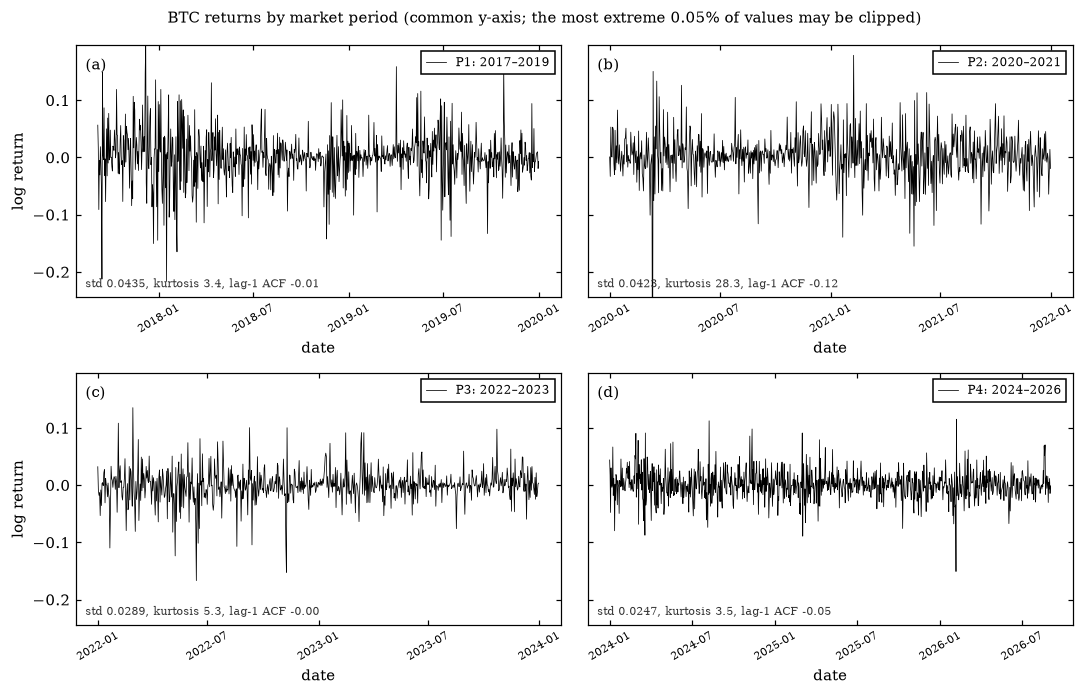

returns: std by period P1 0.0435, P2 0.0423, P3 0.0289, P4 0.0247; ratio max/min = 1.8. Kurtosis P1 3.4, P2 28.3, P3 5.3, P4 3.5. Lag-1 ACF P1 -0.01, P2 -0.12, P3 -0.00, P4 -0.05.


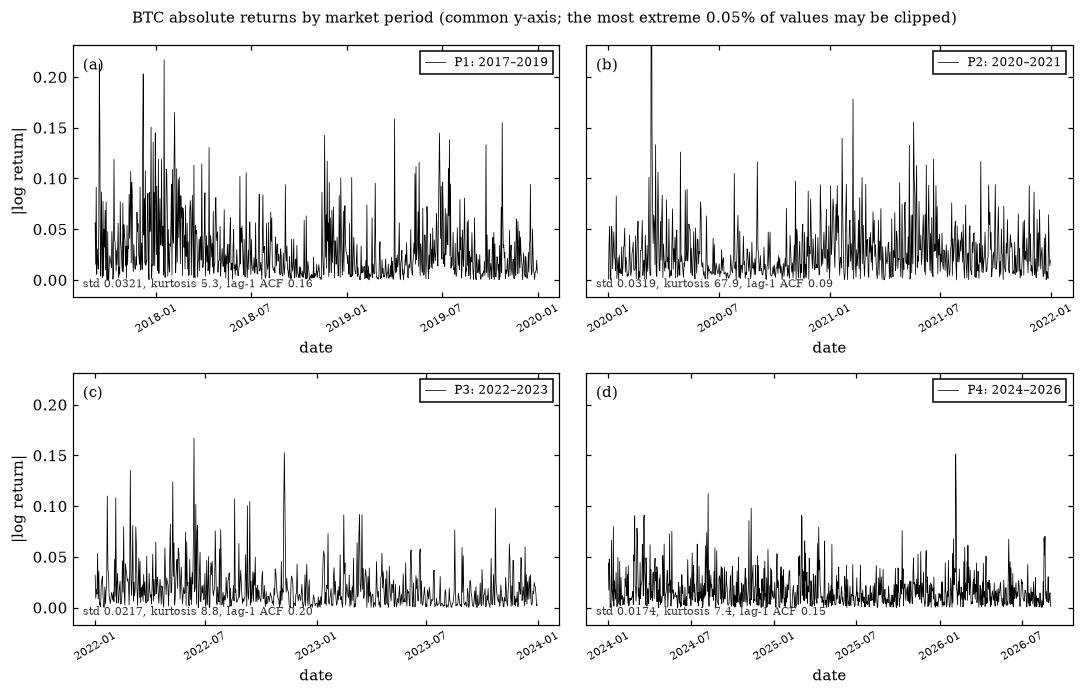

absolute returns: std by period P1 0.0321, P2 0.0319, P3 0.0217, P4 0.0174; ratio max/min = 1.8. Kurtosis P1 5.3, P2 67.9, P3 8.8, P4 7.4. Lag-1 ACF P1 0.16, P2 0.09, P3 0.20, P4 0.15.


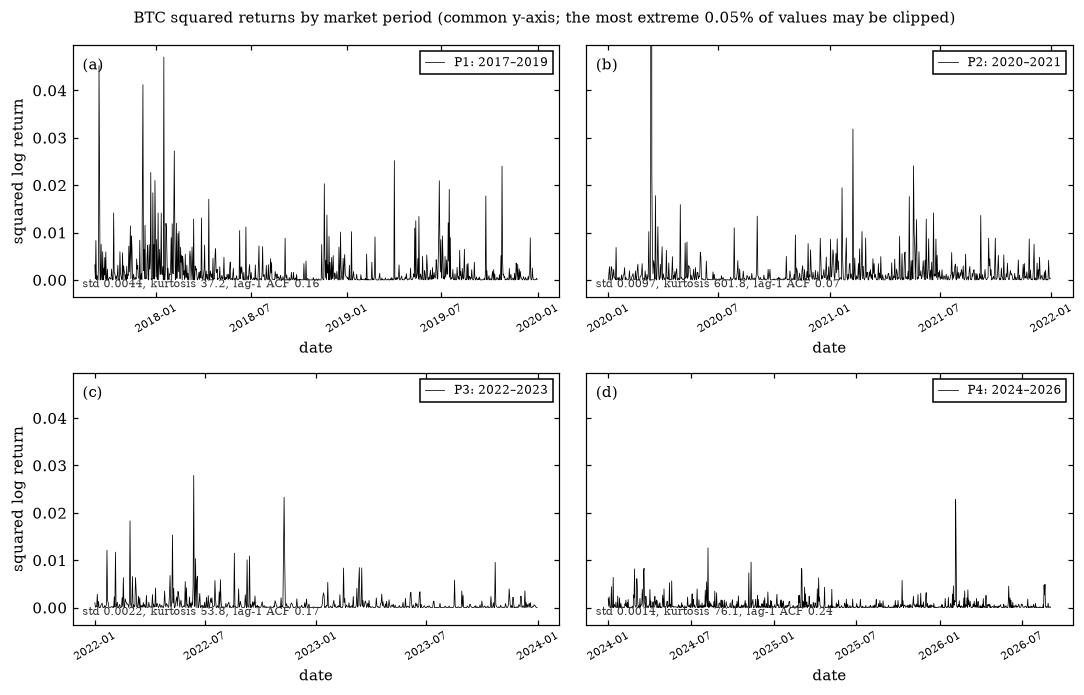

squared returns: std by period P1 0.0044, P2 0.0097, P3 0.0022, P4 0.0014; ratio max/min = 6.8. Kurtosis P1 37.2, P2 601.8, P3 53.8, P4 76.1. Lag-1 ACF P1 0.16, P2 0.07, P3 0.17, P4 0.24.


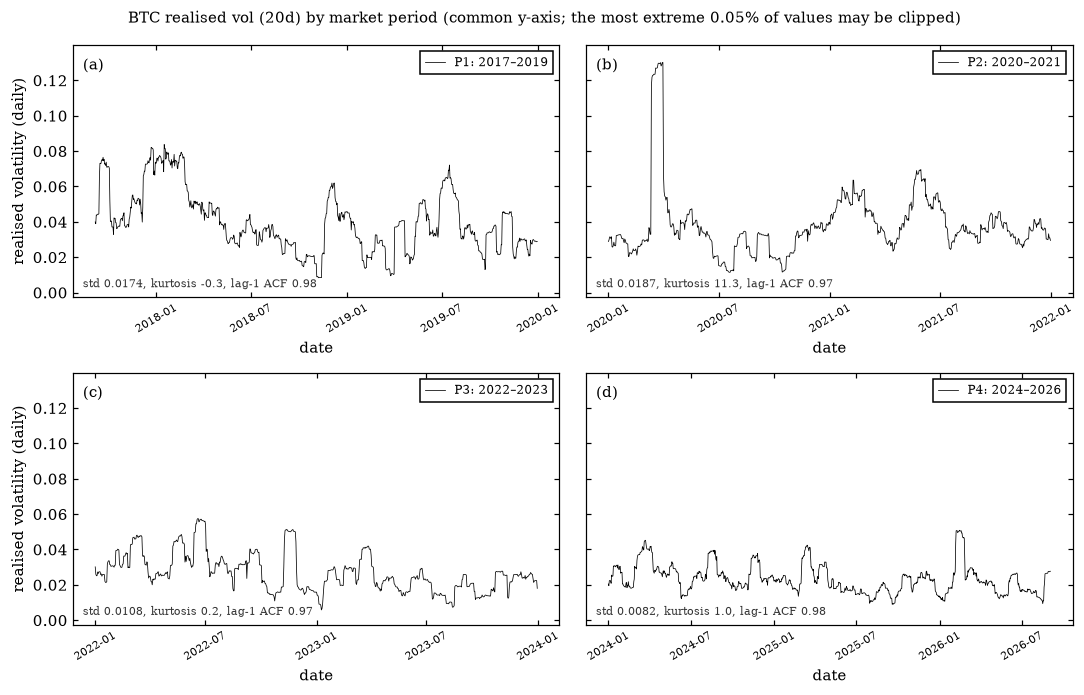

realised vol (20d): std by period P1 0.0174, P2 0.0187, P3 0.0108, P4 0.0082; ratio max/min = 2.3. Kurtosis P1 -0.3, P2 11.3, P3 0.2, P4 1.0. Lag-1 ACF P1 0.98, P2 0.97, P3 0.97, P4 0.98.


In [29]:
# Journal figure style (after Phys. Rev. E 107, 044609, Figs. 3 and 5): serif fonts, framed axes, inward ticks,
# no grid, thin lines, panel letters and boxed legends.
PRE_STYLE = {"font.family": "serif", "font.serif": ["DejaVu Serif", "Times New Roman", "Times"], "mathtext.fontset": "cm",
             "axes.grid": False, "axes.spines.top": True, "axes.spines.right": True, "xtick.direction": "in",
             "ytick.direction": "in", "xtick.top": True, "ytick.right": True, "font.size": 10, "axes.linewidth": 0.8,
             "legend.frameon": True, "legend.edgecolor": "black", "legend.fancybox": False, "legend.framealpha": 1.0}
PRE_COLS = ["magenta", "blue", "black", "green"]          # bottom to top, as in Fig. 5 of the paper
PLAB = {p: p.split()[0] + ": " + p.split()[1].replace("-", "\u2013") for p in PERIODS}

TS_STATS = []
for k in NAMES:
    v_all = S[k]
    lo_y, hi_y = np.quantile(v_all, 0.0005), np.quantile(v_all, 0.9995)
    pad = 0.08 * (hi_y - lo_y)
    with plt.rc_context(PRE_STYLE):
        fig, ax = plt.subplots(2, 2, figsize=(10, 6.4), sharey=True)
        for a, (j, (p, ix)) in zip(ax.flat, enumerate(PIDX.items())):
            v = v_all[ix]
            st = period_stats(v)
            TS_STATS.append({"series": k, "period": p, "n": len(ix), **st})
            a.plot(dates[ix], v, lw=0.5, color="black", label=PLAB[p])
            a.set_ylim(lo_y - pad, hi_y + pad)
            a.text(0.02, 0.95, f"({'abcd'[j]})", transform=a.transAxes, va="top", fontsize=10)
            a.legend(loc="upper right", fontsize=8, handlelength=1.6)
            a.text(0.02, 0.04, f"std {st['std']:.4f}, kurtosis {st['kurtosis']:.1f}, lag-1 ACF {st['lag-1 ACF']:.2f}",
                   transform=a.transAxes, fontsize=7, color="#333333")
            a.set_xlabel("date")
            if j % 2 == 0:
                a.set_ylabel(UNITS[k])
            a.xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7]))
            a.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%Y-%m"))
            a.tick_params(axis="x", labelsize=7, rotation=30)
        fig.suptitle(f"BTC {k} by market period (common y-axis; the most extreme 0.05% of values may be clipped)", fontsize=10)
        save_psd(fig, f"10_timeseries_periods_{k.replace(' ', '_').replace('(', '').replace(')', '')}")
    tk = pd.DataFrame([r for r in TS_STATS if r["series"] == k]).set_index("period")
    print(f"{k}: std by period " + ", ".join(f"{p.split()[0]} {tk.loc[p, 'std']:.4f}" for p in PIDX)
          + f"; ratio max/min = {tk['std'].max() / tk['std'].min():.1f}. Kurtosis " + ", ".join(f"{p.split()[0]} {tk.loc[p, 'kurtosis']:.1f}" for p in PIDX)
          + ". Lag-1 ACF " + ", ".join(f"{p.split()[0]} {tk.loc[p, 'lag-1 ACF']:.2f}" for p in PIDX) + ".")
TS_STATS = pd.DataFrame(TS_STATS)
TS_STATS.to_csv(PSD_DIR / "period_time_domain_stats.csv", index=False)

**How to read these figures.** Bursts of large values that cluster in time show volatility clustering; a
narrower band with fewer spikes shows a calmer regime. The lines printed above the figures give the numbers
behind the visual impression (standard deviation, kurtosis, lag-1 autocorrelation per period). A regular
oscillation would appear as a repeating pattern of fixed spacing in these panels, and is checked formally in the
spectra below.

### 11.2 Figure-5-style power spectra by period (offset for display)

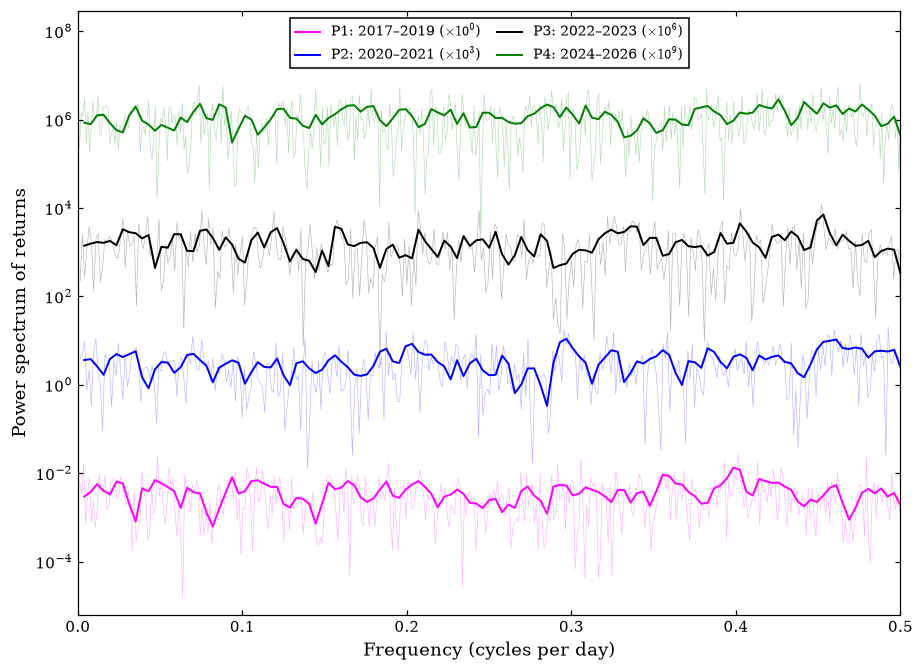

Figure caption (returns): Welch power spectra (thick; thin: periodograms) of BTC returns in four market periods, in (log return)^2 per cycle/day. The ordinates have been multiplied by a scale factor to render them well spaced on the y axis. From bottom to top, the periods (and scale factors) are P1 2017-2019 (10^0), P2 2020-2021 (10^3), P3 2022-2023 (10^6), P4 2024-2026 (10^9).


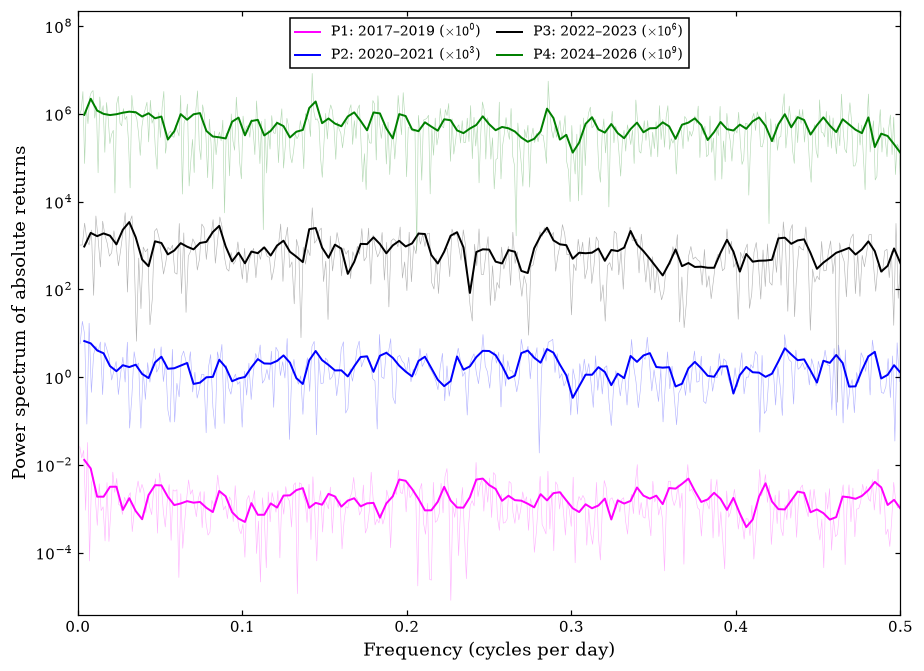

Figure caption (absolute returns): Welch power spectra (thick; thin: periodograms) of BTC absolute returns in four market periods, in (|log return|)^2 per cycle/day. The ordinates have been multiplied by a scale factor to render them well spaced on the y axis. From bottom to top, the periods (and scale factors) are P1 2017-2019 (10^0), P2 2020-2021 (10^3), P3 2022-2023 (10^6), P4 2024-2026 (10^9).


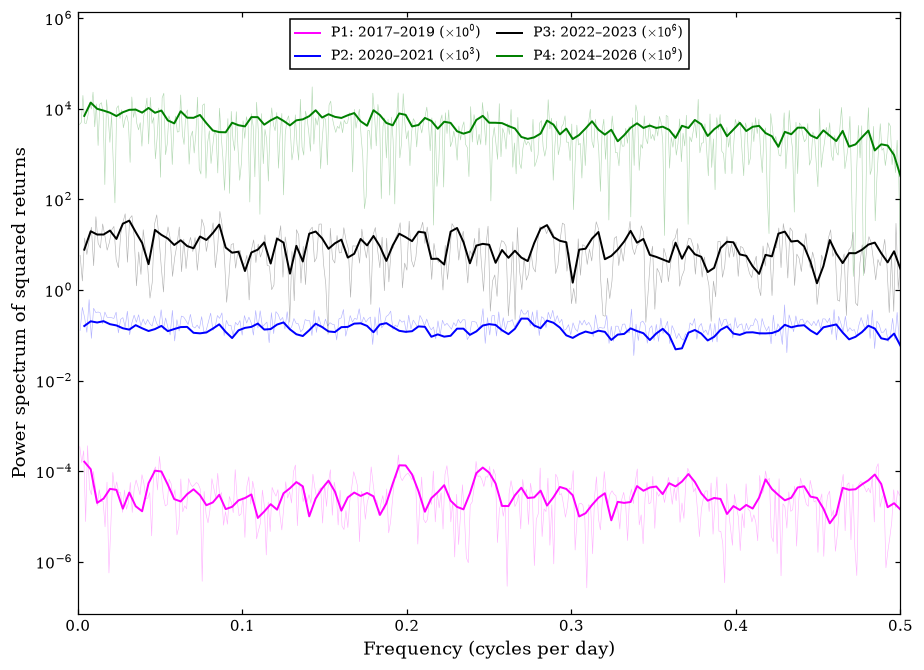

Figure caption (squared returns): Welch power spectra (thick; thin: periodograms) of BTC squared returns in four market periods, in (squared log return)^2 per cycle/day. The ordinates have been multiplied by a scale factor to render them well spaced on the y axis. From bottom to top, the periods (and scale factors) are P1 2017-2019 (10^0), P2 2020-2021 (10^3), P3 2022-2023 (10^6), P4 2024-2026 (10^9).


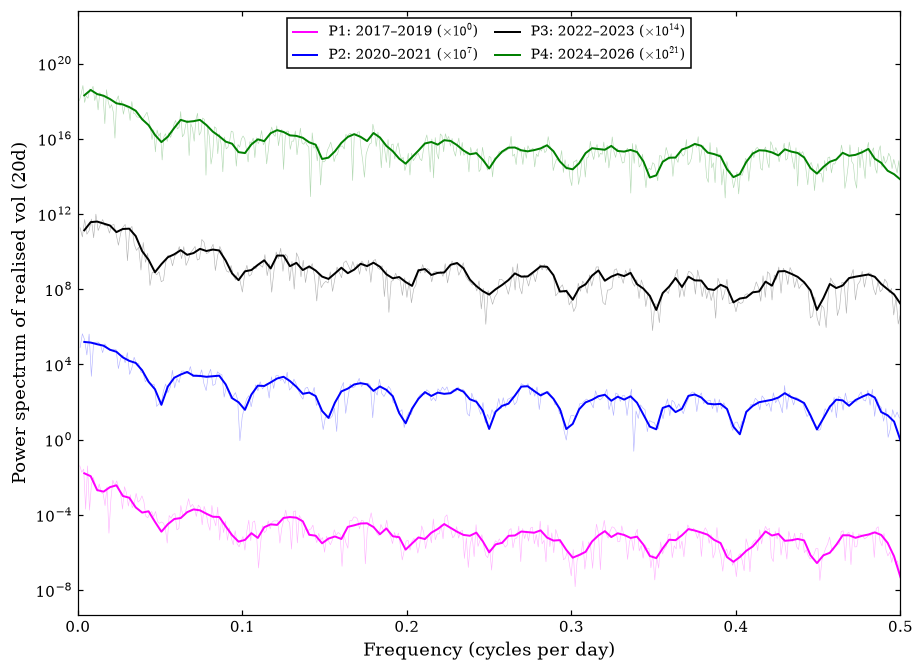

Figure caption (realised vol (20d)): Welch power spectra (thick; thin: periodograms) of BTC realised vol (20d) in four market periods, in (realised volatility (daily))^2 per cycle/day. The ordinates have been multiplied by a scale factor to render them well spaced on the y axis. From bottom to top, the periods (and scale factors) are P1 2017-2019 (10^0), P2 2020-2021 (10^7), P3 2022-2023 (10^14), P4 2024-2026 (10^21).


In [30]:
# Display offsets: curve j (P1 at the bottom) is multiplied by 10^(j * step). The step (in decades) is fixed by a
# rule, not by eye: one decade more than the largest log10 range of any Welch curve of that series, so curves
# cannot overlap. The csv keeps the unscaled values.
PSPEC, PSD_ROWS, OFFSETS = {}, [], {}
for k in NAMES:
    curves = {}
    for p, ix in PIDX.items():
        v = S[k][ix]
        f, P = T.psd_welch(v, NPERSEG_P, standardised=False)
        fp, Pp = T.psd_periodogram(v, standardised=False)
        fz, Pz = T.psd_welch(v, NPERSEG_P)                     # standardised, for the tests
        PSPEC[(k, p)] = {"f": f, "P": P, "fp": fp, "Pp": Pp, "Pz": Pz}
        curves[p] = (f, P, fp, Pp)
        PSD_ROWS += [{"series": k, "period": p, "frequency": fi, "welch_psd": Pi} for fi, Pi in zip(f, P)]
    step = int(np.ceil(max(np.log10(c[1].max()) - np.log10(c[1].min()) for c in curves.values()))) + 1
    OFFSETS[k] = {p: j * step for j, p in enumerate(PIDX)}
    with plt.rc_context(PRE_STYLE):
        fig, ax = plt.subplots(figsize=(8.5, 6.2))
        for j, (p, (f, P, fp, Pp)) in enumerate(curves.items()):
            sc = 10.0 ** OFFSETS[k][p]
            ax.semilogy(fp, Pp * sc, lw=0.4, color=PRE_COLS[j], alpha=0.3)
            ax.semilogy(f, P * sc, lw=1.3, color=PRE_COLS[j], label=f"{PLAB[p]} ($\\times 10^{{{OFFSETS[k][p]}}}$)")
        ymin = min((c[1] * 10.0 ** OFFSETS[k][p]).min() for p, c in curves.items())
        ymax = max((c[1] * 10.0 ** OFFSETS[k][p]).max() for p, c in curves.items())
        ax.set_ylim(ymin / 100, ymax * 10 ** max(2, 0.6 * step))
        ax.set_xlim(0, 0.5)
        ax.set_xlabel("Frequency (cycles per day)", fontsize=12)
        ax.set_ylabel(f"Power spectrum of {k}", fontsize=12)
        ax.legend(loc="upper center", ncol=2, fontsize=9, handlelength=1.8, columnspacing=1.2)
        save_psd(fig, f"11_spectra_periods_{k.replace(' ', '_').replace('(', '').replace(')', '')}")
    print(f"Figure caption ({k}): Welch power spectra (thick; thin: periodograms) of BTC {k} in four market periods, in "
          f"({UNITS[k]})^2 per cycle/day. The ordinates have been multiplied by a scale factor to render them well spaced "
          f"on the y axis. From bottom to top, the periods (and scale factors) are "
          + ", ".join(f"{p} (10^{OFFSETS[k][p]})" for p in PIDX) + ".")
pd.DataFrame(PSD_ROWS).to_csv(PSD_DIR / "period_welch_psd_unscaled.csv", index=False)

In [31]:
PER_ROWS = []
for k in NAMES:
    for p, ix in PIDX.items():
        sp = PSPEC[(k, p)]
        lo_sh, hi_sh = T.band_shares(sp["f"], sp["Pz"])
        beta, se, r2, npts = T.spectral_slope(sp["f"], sp["Pz"], SLOPE_P)
        pk = T.spectral_peaks(sp["f"], sp["Pz"], 3, fmin=2 / NPERSEG_P)
        PER_ROWS.append({"series": k, "period": p, "low share (>20 d)": lo_sh, "high share (<5 d)": hi_sh,
                         "beta (25-128 d)": beta, "beta R^2": r2,
                         "dominant period (d)": pk[0][1] if pk else np.nan,
                         "top peaks (d)": ", ".join(f"{q[1]:.1f}" for q in pk)})
PER = pd.DataFrame(PER_ROWS)
for k in NAMES:
    t = PER[PER.series == k].set_index("period")
    print(f"{k}: low-band share " + ", ".join(f"{p.split()[0]} {t.loc[p, 'low share (>20 d)']:.2f}" for p in PIDX)
          + "; high-band share " + ", ".join(f"{p.split()[0]} {t.loc[p, 'high share (<5 d)']:.2f}" for p in PIDX)
          + "; dominant period (d) " + ", ".join(f"{p.split()[0]} {t.loc[p, 'dominant period (d)']:.1f}" for p in PIDX) + ".")

returns: low-band share P1 0.09, P2 0.08, P3 0.10, P4 0.07; high-band share P1 0.60, P2 0.66, P3 0.62, P4 0.62; dominant period (d) P1 2.5, P2 3.4, P3 2.2, P4 2.3.
absolute returns: low-band share P1 0.14, P2 0.12, P3 0.15, P4 0.16; high-band share P1 0.58, P2 0.58, P3 0.51, P4 0.50; dominant period (d) P1 4.1, P2 2.3, P3 32.0, P4 128.0.
squared returns: low-band share P1 0.11, P2 0.11, P3 0.15, P4 0.17; high-band share P1 0.57, P2 0.56, P3 0.52, P4 0.43; dominant period (d) P1 5.1, P2 3.7, P3 32.0, P4 128.0.
realised vol (20d): low-band share P1 0.94, P2 0.93, P3 0.92, P4 0.93; high-band share P1 0.01, P2 0.02, P3 0.02, P4 0.01; dominant period (d) P1 42.7, P2 15.1, P3 85.3, P4 128.0.


**How to read the spectra.** A flat curve means power spread evenly over all frequencies (broadband, like white
noise). A curve rising towards the left means more power at long periods (persistence, long memory). A narrow
spike that stands out by an order of magnitude and appears in several periods at the same frequency would be a
candidate periodic component. Because the curves are offset, compare **shapes** across periods, not heights; the
heights in the unscaled csv also reflect each period's volatility level. Whether any peak or shape is unusual is
decided by the surrogate tests below, not by eye.

**Built-in artifact in realised volatility.** A 20-day moving average has a frequency response
$|\sin(20\pi f) / (20 \sin(\pi f))|^2$ with zeros at $f = 0.05, 0.10, 0.15, \dots$ cycles per day. The regular dips
of the realised-volatility spectra at exactly those frequencies, and the bumps between them, come from this
window, not from any cycle in the market. The GARCH surrogates of realised volatility are built with the same
window, so the tests below compare like with like.

### 11.3 Period spectra against IAAFT and GARCH surrogates

period surrogate spectra: 29 s (499 per family, period and series)


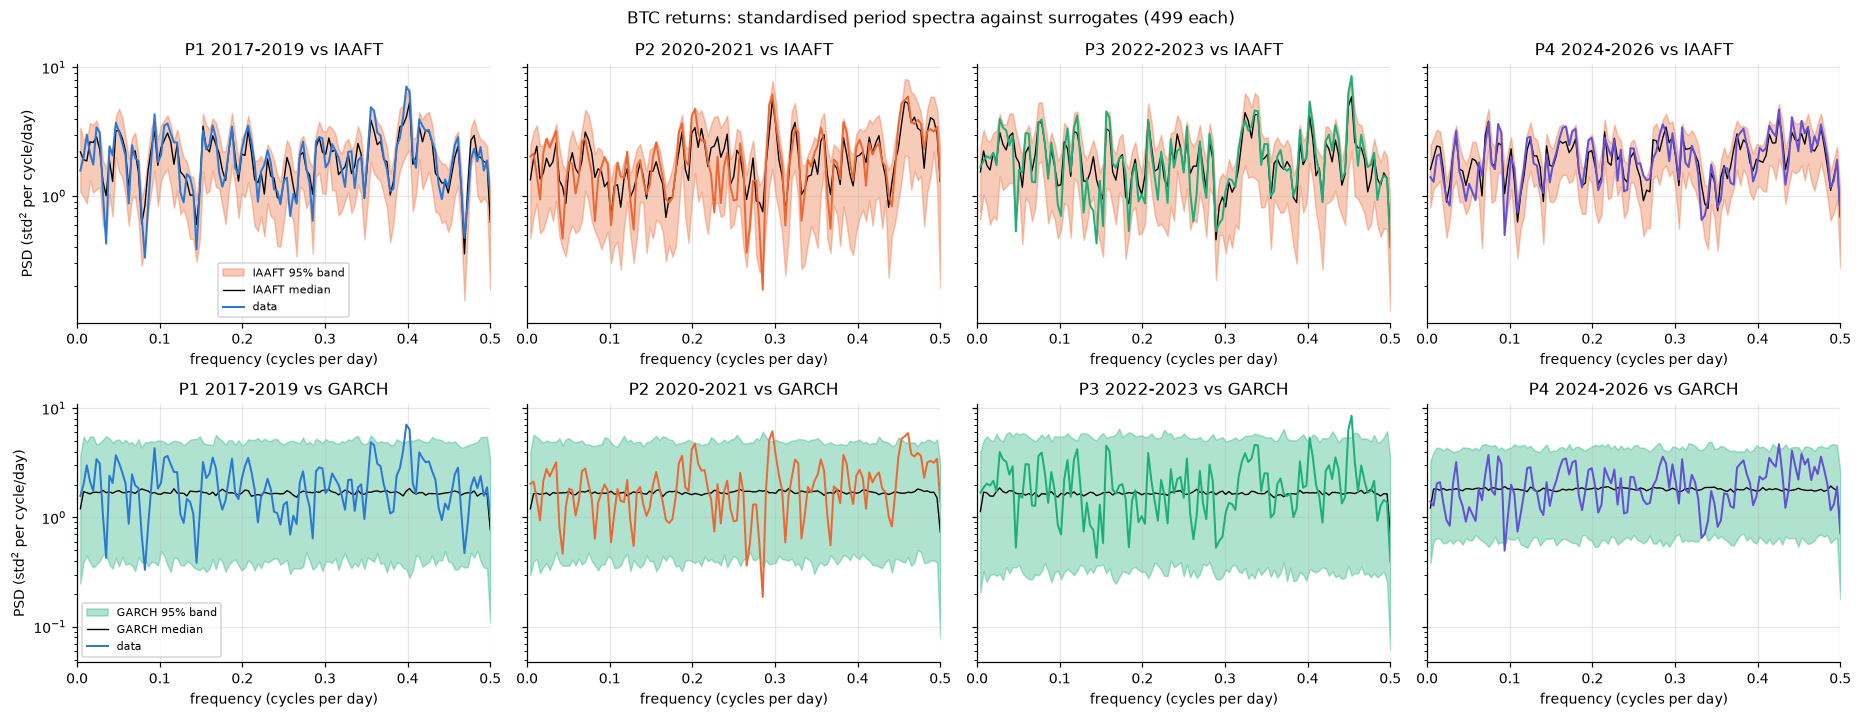

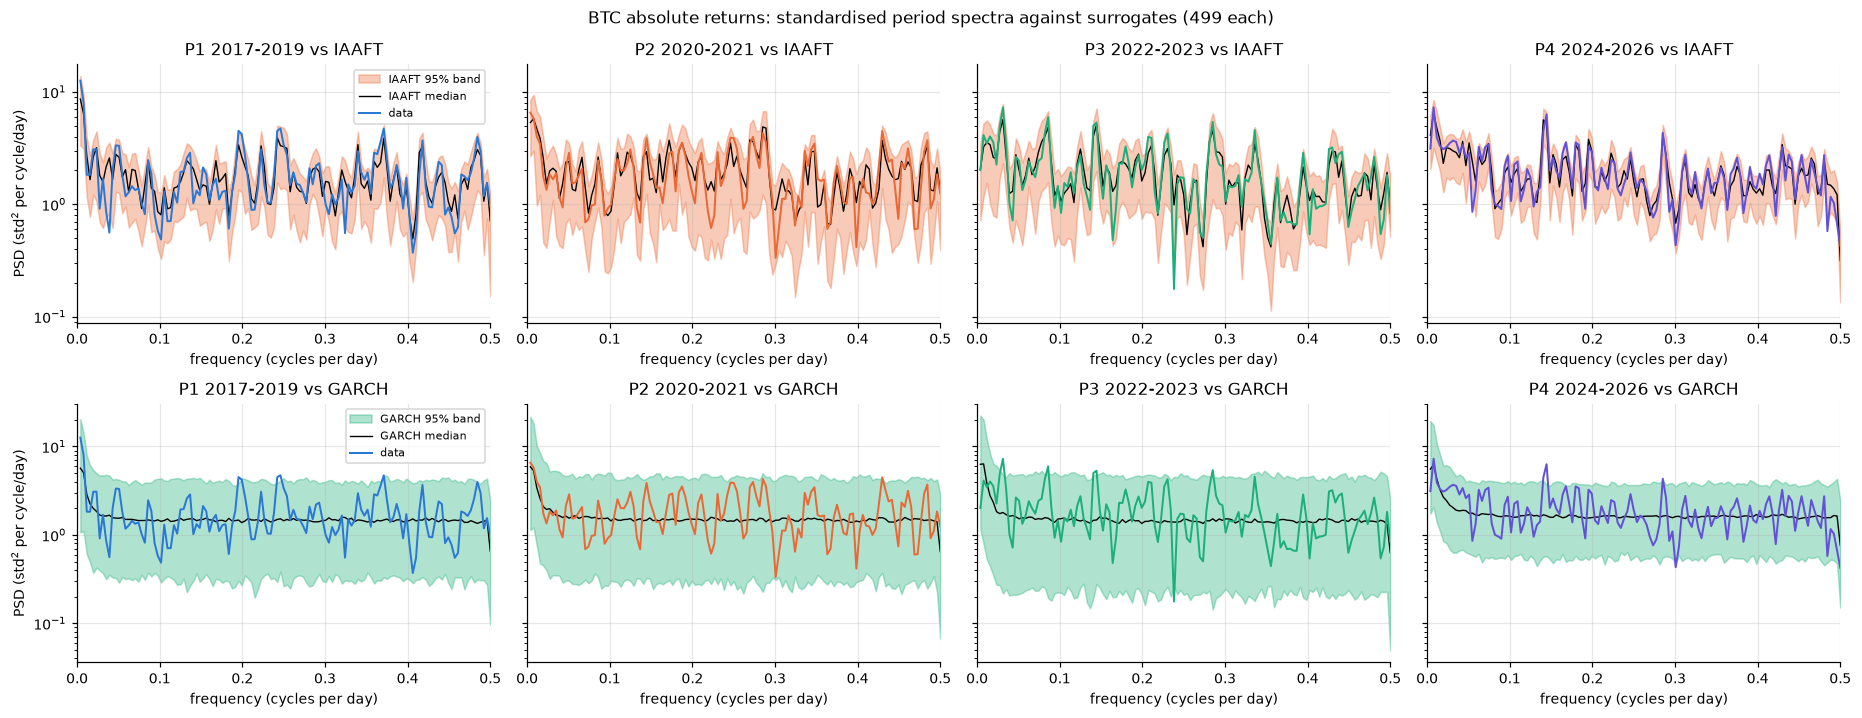

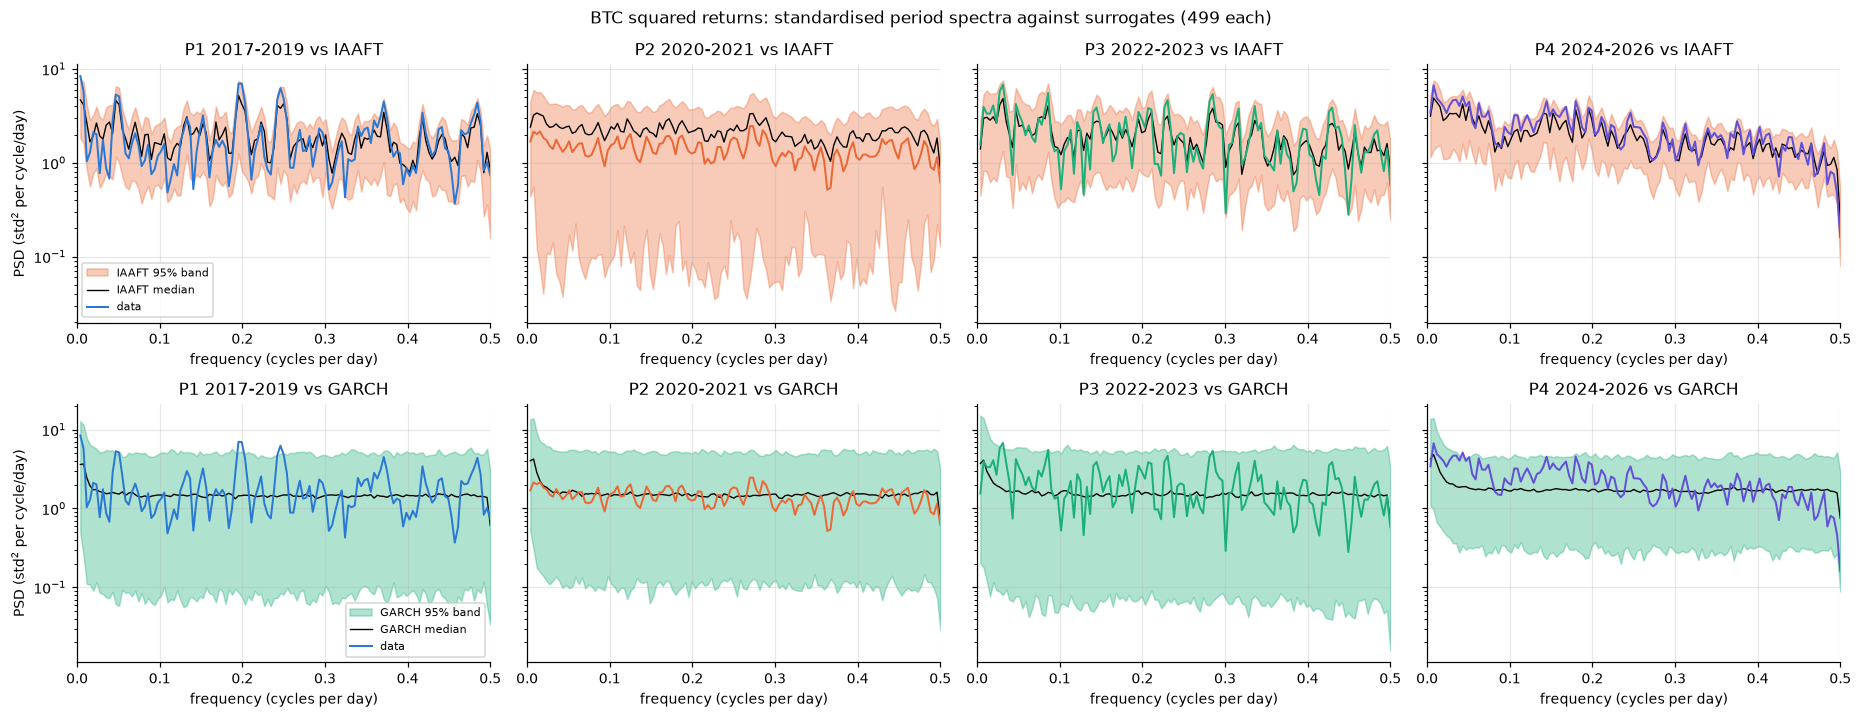

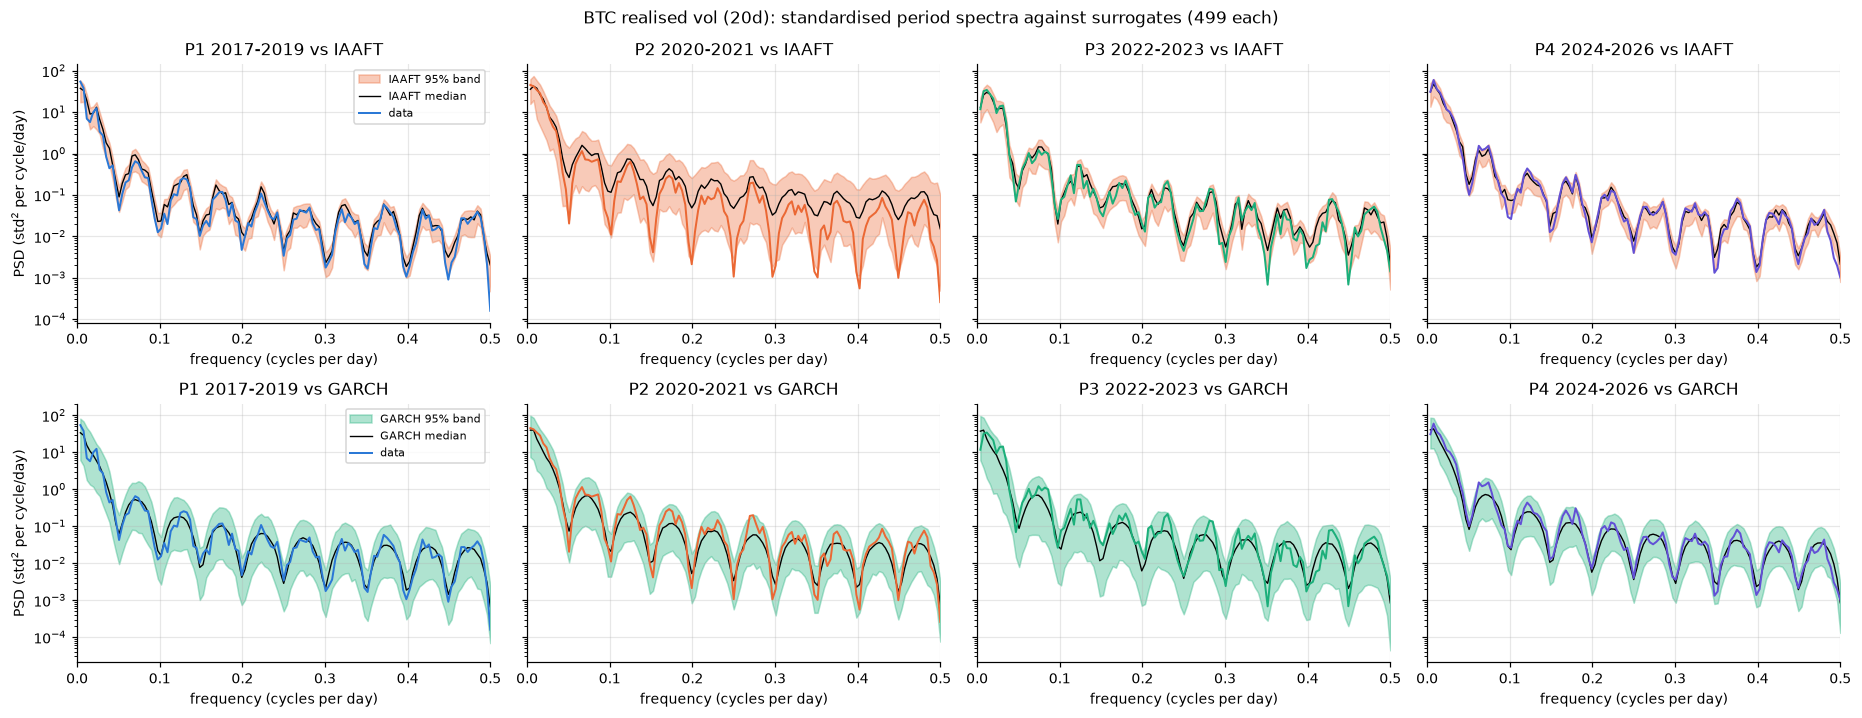

In [32]:
t0 = time.time()
PSURR = {}
for k in NAMES:
    for j, (p, ix) in enumerate(PIDX.items()):
        r_ext = r_full.values[ix[0]: ix[-1] + RV_WINDOW]          # 19 warm-up days + the period
        PSURR[(k, p)] = T.period_spectra_surrogates(S[k][ix], r_ext, k, make_series, N_SURR_P,
                                                     [SEED, 11, NAMES.index(k), j], NPERSEG_P, SLOPE_P, RV_WINDOW - 1)
print(f"period surrogate spectra: {time.time() - t0:.0f} s ({N_SURR_P} per family, period and series)")

for k in NAMES:
    fig, ax = plt.subplots(2, 4, figsize=(17, 6.6), sharey="row")
    for j, p in enumerate(PIDX):
        sp, su = PSPEC[(k, p)], PSURR[(k, p)]
        for i, kind in enumerate(["iaaft", "garch"]):
            a = ax[i, j]
            lo, med, hi = np.quantile(su[kind]["P"], [0.025, 0.5, 0.975], axis=0)
            a.fill_between(sp["f"], lo, hi, color=ORANGE if kind == "iaaft" else GREEN, alpha=0.35, label=f"{kind.upper()} 95% band")
            a.semilogy(sp["f"], med, color="black", lw=0.9, label=f"{kind.upper()} median")
            a.semilogy(sp["f"], sp["Pz"], color=PCOL[p], lw=1.3, label="data")
            a.set(title=f"{p} vs {kind.upper()}", xlabel="frequency (cycles per day)",
                  ylabel="PSD (std$^2$ per cycle/day)" if j == 0 else None, xlim=(0, 0.5))
            if j == 0: a.legend(fontsize=7)
    fig.suptitle(f"BTC {k}: standardised period spectra against surrogates (499 each)", fontsize=11)
    save_psd(fig, f"12_period_surrogates_{k.replace(' ', '_').replace('(', '').replace(')', '')}")

In [33]:
TEST_ROWS = []
for k in NAMES:
    for p in PIDX:
        sp, su = PSPEC[(k, p)], PSURR[(k, p)]
        row = PER[(PER.series == k) & (PER.period == p)].iloc[0].to_dict()
        for kind in ["iaaft", "garch"]:
            pg, D, out = T.envelope_test(sp["Pz"], su[kind]["P"])
            row[f"global p vs {kind.upper()}"] = pg
            row[f"outside {kind.upper()} band"] = out
        g = su["garch"]
        row["p low share vs GARCH"] = T.p_value(row["low share (>20 d)"], g["low"], "two-sided")
        row["p beta vs GARCH"] = T.p_value(row["beta (25-128 d)"], g["beta"], "two-sided")
        hi97 = np.quantile(g["P"], 0.975, axis=0)
        ip = int(np.argmin(np.abs(sp["f"] - 1 / row["dominant period (d)"])))
        row["dominant peak above GARCH 97.5%"] = bool(sp["Pz"][ip] > hi97[ip])
        row["GARCH alpha+beta"] = float(su["garch_params"]["alpha[1]"] + su["garch_params"]["beta[1]"])
        TEST_ROWS.append(row)
PT = pd.DataFrame(TEST_ROWS)
gcols = ["global p vs GARCH", "p low share vs GARCH", "p beta vs GARCH"]
q = T.bh(PT[gcols].values.ravel()).reshape(len(PT), len(gcols))
for j, c in enumerate(gcols):
    PT["q " + c.replace("p ", "", 1) if c.startswith("p ") else "q " + c] = q[:, j]
PT.to_csv(PSD_DIR / "period_spectrum_tests.csv", index=False)
show = ["series", "period", "low share (>20 d)", "high share (<5 d)", "beta (25-128 d)", "dominant period (d)",
        "dominant peak above GARCH 97.5%", "global p vs IAAFT", "global p vs GARCH", "q global p vs GARCH",
        "q low share vs GARCH", "q beta vs GARCH", "GARCH alpha+beta"]
PT[show].round(3)

,series,period,low share (>20 d),high share (<5 d),beta (25-128 d),dominant period (d),dominant peak above GARCH 97.5%,global p vs IAAFT,global p vs GARCH,q global p vs GARCH,q low share vs GARCH,q beta vs GARCH,GARCH alpha+beta
0,returns,P1 2017-2019,0.090,0.602,0.439,2.510,True,0.660,0.350,0.933,0.933,0.933,1.000
1,returns,P2 2020-2021,0.078,0.659,-0.106,3.368,True,0.448,0.208,0.933,0.933,0.933,0.988
2,returns,P3 2022-2023,0.100,0.618,-0.352,2.207,True,0.566,0.752,0.933,0.933,0.933,1.000
3,returns,P4 2024-2026,0.068,0.625,-0.091,2.349,True,0.816,0.592,0.933,0.933,0.933,0.968
4,absolute returns,P1 2017-2019,0.137,0.583,1.209,4.063,True,0.292,0.726,0.933,0.933,0.933,1.000
5,absolute returns,P2 2020-2021,0.115,0.581,0.916,2.327,True,0.548,0.788,0.933,0.933,0.933,0.988
6,absolute returns,P3 2022-2023,0.147,0.509,0.291,32.000,True,0.506,0.296,0.933,0.933,0.933,1.000
7,absolute returns,P4 2024-2026,0.159,0.495,0.373,128.000,False,0.172,0.478,0.933,0.933,0.933,0.968
8,squared returns,P1 2017-2019,0.108,0.572,0.846,5.120,True,0.400,0.664,0.933,0.948,0.933,1.000
9,squared returns,P2 2020-2021,0.106,0.560,0.247,3.710,False,0.526,0.970,0.970,0.933,0.933,0.988


**How to read the test table.** "global p" asks whether the whole spectrum of a period lies outside what the
surrogate model produces (one test over all frequencies, so a single random spike does not count). The low-band
share and the slope ask whether the period has more long-period power or a steeper power law than GARCH gives.
q-values are FDR-adjusted over all GARCH tests in this section. A dominant peak above the pointwise band without a
global rejection is what chance alone produces at roughly 3 of 128 frequencies.

### 11.4 Interpretation of the period analysis (generated from the results above)

In [34]:
def regime_summary():
    out = []
    t = PT.set_index(["series", "period"])
    sig_any = PT[(PT[[c for c in PT.columns if c.startswith("q ")]] < ALPHA).any(axis=1)]
    for k in NAMES:
        s_ = TS_STATS[TS_STATS.series == k].set_index("period")["std"]
        out.append(f"{k}: std ranges from {s_.min():.4f} ({s_.idxmin().split()[0]}) to {s_.max():.4f} ({s_.idxmax().split()[0]}); "
                   f"low-band share " + ", ".join(f"{p.split()[0]} {t.loc[(k, p), 'low share (>20 d)']:.2f}" for p in PIDX)
                   + "; global GARCH test q " + ", ".join(f"{p.split()[0]} {t.loc[(k, p), 'q global p vs GARCH']:.2f}" for p in PIDX) + ".")
    peaks_sig = PT[PT["dominant peak above GARCH 97.5%"] & (PT["q global p vs GARCH"] < ALPHA)]
    out.append("")
    out.append("Periodic components (dominant peak above the GARCH band AND global test rejected after FDR): "
               + (", ".join(f"{a} {b}" for a, b in zip(peaks_sig.series, peaks_sig.period)) if len(peaks_sig) else "none") + ".")
    out.append("Any spectral statistic beyond GARCH after FDR: "
               + (", ".join(f"{a} {b}" for a, b in zip(sig_any.series, sig_any.period)) if len(sig_any) else "none") + ".")
    return "\n".join(out)
print(regime_summary())

returns: std ranges from 0.0247 (P4) to 0.0435 (P1); low-band share P1 0.09, P2 0.08, P3 0.10, P4 0.07; global GARCH test q P1 0.93, P2 0.93, P3 0.93, P4 0.93.
absolute returns: std ranges from 0.0174 (P4) to 0.0321 (P1); low-band share P1 0.14, P2 0.12, P3 0.15, P4 0.16; global GARCH test q P1 0.93, P2 0.93, P3 0.93, P4 0.93.
squared returns: std ranges from 0.0014 (P4) to 0.0097 (P2); low-band share P1 0.11, P2 0.11, P3 0.15, P4 0.17; global GARCH test q P1 0.93, P2 0.97, P3 0.93, P4 0.93.
realised vol (20d): std ranges from 0.0082 (P4) to 0.0187 (P2); low-band share P1 0.94, P2 0.93, P3 0.92, P4 0.93; global GARCH test q P1 0.93, P2 0.93, P3 0.93, P4 0.93.

Periodic components (dominant peak above the GARCH band AND global test rejected after FDR): none.
Any spectral statistic beyond GARCH after FDR: none.


## 12. Interpretation of the power-spectrum and period analysis (written for the run on BTC daily, 2017-09-06 to 2026-09-02)

**Periodicity in returns.** None. The return spectrum is flat (beta = -0.14, R^2 = 0.13; GPH beta = 0.01), its
largest peaks (2.5, 2.8, 3.4 days) are not above the GARCH band, the weekly component is absent (q = 0.98) and the
whole-spectrum test does not reject (q = 0.84). In every period the return spectrum stays broadband.

**Low-frequency power in volatility.** Yes. Periods above 20 days carry 16% of the power of absolute returns,
13% of squared returns and 94% of realised volatility, against 9% for returns (white noise: about 10%). For
realised volatility most of this is built in by the 20-day window.

**Long-memory-like behaviour.** The volatility spectra follow a rough power law at low frequencies: beta = 0.67
for absolute returns (GPH 1.14) and 1.66 for realised volatility (GPH 0.98). But the GARCH surrogates give the
same or steeper slopes (absolute returns 0.85, realised volatility 1.96; p = 0.52 and 0.25). The fitted GARCH is
practically integrated (alpha + beta = 1.000), and such a process produces long-memory-like spectra over a finite
sample. The slopes are therefore consistent with persistent stochastic volatility; they do not demonstrate true
long memory, and they say nothing about chaos.

**What GARCH does not explain: a weekly cycle in volatility.** The one spectral feature beyond GARCH after FDR
is a peak at exactly 7 days in absolute returns (q = 0.016) and in realised volatility (q = 0.04). A 7-day period
in crypto volatility is a calendar effect (lower activity and volatility at weekends) that a GARCH model without
day-of-week terms cannot produce. This is genuine periodic structure, but it is seasonality with a known cause,
not periodic or chaotic dynamics. The whole-spectrum tests do not reject for any series (q >= 0.79), so apart from
this narrow weekly line the spectra are what GARCH produces.

**Changes across market periods.** The level of volatility changes a lot (return standard deviation falls from
0.044 in 2017-2019 to 0.025 in 2024-2026; kurtosis jumps to 28 in 2020-2021 because of the COVID crash), but the
**shape** of the spectra stays the same: returns flat in every period, volatility rising at low frequencies in
every period. No period spectrum differs from its own GARCH surrogates (all q = 0.93 or more), and no period has a
dominant peak that survives the global test.

**Additional frequency-domain structure.** Only the weekly volatility cycle. A broadband spectrum is not taken as
evidence of chaos (noise is also broadband), and the 7-day peak is not taken as evidence of periodic dynamics.
Next step for this finding: add a day-of-week term to the volatility model (or remove day-of-week means from
absolute returns) and check that the weekly peak disappears.
